# Le réseau ferré français vu comme un graphe

*Projet du cours* Metabolic networks / Graph analysis *(C. Frainay, F. Jourdan, INRAE Toxalim).*

Ce rapport applique les méthodes d'analyse de graphes du cours à un autre réseau réel : le réseau ferré national (RFN), c'est-à-dire l'ensemble des voies ferrées gérées par SNCF Réseau. Chaque question suit la démarche du cours. On définit d'abord ce que représentent les nœuds et les arêtes, puis on prétraite le graphe (*« careful relevance assessment of nodes and edges, followed by graph pre-processing is always required »*). On choisit ensuite une métrique du cours, puis la visualisation qui répond à la question (*« one tailored visualization for each type of analysis »*). Chaque question est traitée par une figure, suivie d'une légende qui décrit le dessin et donne la réponse.

| Question | Notion du cours | Figure |
|---|---|---|
| Q1. Où sont les lignes à grande vitesse ? | attributs des arêtes | 1 |
| Q2. Où circulent les trains ? | graphe pondéré | 2 |
| Q3. Quelles villes sont proches de tout le réseau ? | closeness, farness | 3 |
| Q4. Où sont le centre et la périphérie ? | excentricité, rayon, diamètre | 4 |
| Q5. Quels sont les points névralgiques ? | betweenness des nœuds et des arêtes | 5 |
| Q6. Que se passe-t-il si on retire les villes les plus importantes ? | robustesse, points d'articulation | 6 |
| Q7. Quels trajets la promotion emprunte-t-elle vers Rouen ? | plus court chemin pondéré, sous-graphe, vue schématique | 7 |
| Q8. Les régions sont-elles inégalement desservies ? | attributs des nœuds, graphe quotient | 8 |
| Q9. Quelles villes ne sont pas connectées ? | composantes connexes | 9 |
| Q10. Quelles gares sont les plus et les moins connectées ? | degré, distribution des degrés | 10 |
| Q11. Quel trajet passe obligatoirement par le plus de gares ? | plus court chemin non pondéré | 11 |
| Contrôle : Cytoscape calcule-t-il la même chose ? | métriques avec et sans poids | tableau |

## 1. Données et construction du graphe

Quelques termes reviennent tout au long du rapport. Une LGV est une ligne à grande vitesse. Le point kilométrique (PK) d'une gare est sa position le long de sa ligne, en km depuis l'origine de la ligne. Le GTFS est le format standard des horaires de transport public. Transilien et RER désignent les trains de banlieue d'Île-de-France, absents des horaires SNCF utilisés ici. Les codes UIC et INSEE sont les identifiants officiels d'une gare et d'une commune.

| Fichier brut | Source | Information retenue |
|---|---|---|
| `liste-des-gares.csv` | [SNCF Réseau](https://ressources.data.sncf.com/explore/dataset/liste-des-gares/) | gares voyageurs : code UIC, nom, commune, département, ligne et PK, coordonnées |
| `fichier-de-formes-des-voies-du-reseau-ferre-national.csv` | [SNCF Réseau](https://ressources.data.sncf.com/explore/dataset/fichier-de-formes-des-voies-du-reseau-ferre-national/) | tracé de chaque tronçon de voie : où les lignes se raccordent |
| `vitesse-maximale-nominale-sur-ligne.csv` | [SNCF Réseau](https://ressources.data.sncf.com/explore/dataset/vitesse-maximale-nominale-sur-ligne/) | vitesse maximale par ligne : itinéraire le plus rapide d'un train |
| `lignes-par-statut.csv` | [SNCF Réseau](https://ressources.data.sncf.com/explore/dataset/lignes-par-statut/) | tracé et statut (exploitée, fermée…) : longueur le long de la voie, part sur LGV |
| `frequentation-gares.csv` | [SNCF Voyageurs](https://ressources.data.sncf.com/explore/dataset/frequentation-gares/) | voyageurs par gare en 2025 |
| `Export_OpenData_SNCF_GTFS_NewTripId.zip` | [SNCF Voyageurs, GTFS](https://ressources.data.sncf.com/explore/dataset/horaires-sncf/) | trains d'un mardi type (01/12/2026) : TER, TGV, Intercités |
| `communes.json`, `departements.json`, `regions.json` | [Etalab](https://github.com/etalab/decoupage-administratif) | code INSEE, population, département et région de chaque commune |

Les codes des LGV sont les numéros de ligne relevés dans les articles Wikipédia de chaque LGV, vérifiés par la longueur mesurée dans les données (par exemple 422 km pour la LGV Est, ligne 005000).

Le script `preprocessing_datasets.py` construit le graphe en trois temps. Il relie d'abord deux gares voisines sur une même ligne, ordonnées par PK, et raccorde les lignes entre elles aux bifurcations repérées sur les tracés. Il projette ensuite chaque train du GTFS sur l'itinéraire le plus rapide entre ses arrêts, ce qui donne le nombre de trains par jour de chaque liaison. Enfin, hypothèse de modélisation centrale, il regroupe toutes les gares d'une même commune en un seul nœud, appelé ville (Paris compte 31 gares, Lyon 6), et mesure chaque liaison le long du tracé. Le script vérifie la table (doublons, boucles, liaisons vers une ville inconnue, tracés incohérents) puis écrit `villes.csv` (les nœuds), `liaisons.csv` (les arêtes) et le fichier Cytoscape.

Le fichier Cytoscape `data/genere/reseau_villes.cyjs` (format JSON de Cytoscape.js) est écrit directement à partir de ces deux tables. Chaque ligne de `villes.csv` devient un nœud (2 597 villes) qui garde toutes ses colonnes comme attributs, plus `cle` (identifiant de la ville) et `name` (son nom). Chaque ligne de `liaisons.csv` devient une arête (3 182 liaisons) avec toutes ses colonnes, plus `cle` = `source~target` et `interaction` = `rail`. La position de chaque nœud est fixée dans le fichier (`x = lon × 100`, `y = −lat × 145`), si bien que le réseau s'ouvre comme une carte de France. La colonne `cle` sert à ajouter dans Cytoscape, comme nouvelles colonnes, les résultats calculés en Python.

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

DONNEES = Path("data/genere")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

villes = pd.read_csv(DONNEES / "villes.csv", dtype={"id": str, "departement": str, "region": str}).set_index("id")
liaisons = pd.read_csv(DONNEES / "liaisons.csv", dtype={"source": str, "target": str, "code_ligne": str})
print(f"{len(villes)} villes, {len(liaisons)} liaisons")
display(villes.head())
display(liaisons.head())

2597 villes, 3182 liaisons


,nom,departement,region,lon,lat,nb_gares,voyageurs_2025,population,nb_trains_jour,desservie,statut_desserte,reseau_principal
id,,,,,,,,,,,,
75056,Paris,75,11,2.356622,48.881053,31,793313445.0,2103778.0,957.0,NaN,inconnue (IDF),True
69123,Lyon,69,84,4.860201,45.760541,6,62858165.0,519127.0,874.0,True,desservie,True
91326,Juvisy-sur-Orge,91,11,2.383583,48.689257,1,41634282.0,19292.0,230.0,NaN,inconnue (IDF),True
93066,Saint-Denis,93,11,2.345561,48.935112,5,76118907.0,149077.0,522.0,NaN,inconnue (IDF),True
93005,Aulnay-sous-Bois,93,11,2.494081,48.932258,1,33692260.0,87599.0,58.0,NaN,inconnue (IDF),True


,source,target,code_ligne,type_ligne,lgv,part_lgv,nb_trains_jour,longueur_km,distance_km,distance_trace_km,vol_oiseau_km,detour
0,93031,MONTMAGNY|SEINE-SAINT-DENIS,"330000,960000",classique,False,NaN,37,0.241,0.241,NaN,0.117,NaN
1,69044,69250,782000,classique,False,0.0,87,0.836,0.823,0.836,0.823,1.016
2,13108,30032,"810000,830356",classique,False,0.0,28,0.840,0.839,0.840,0.804,1.045
3,59013,59602,268000,classique,False,NaN,0,0.873,0.873,NaN,0.868,NaN
4,92026,92062,973000,classique,False,0.0,0,0.971,0.896,0.971,0.896,1.084


Dans `liaisons.csv`, `type_ligne` vaut LGV si plus de la moitié du tracé est sur LGV (`part_lgv`), `nb_trains_jour` compte les trains des deux sens, et `longueur_km`, le poids des arêtes, est la longueur le long du tracé (à défaut, celle donnée par les PK). Les colonnes `distance_km`, `distance_trace_km`, `vol_oiseau_km` et `detour` (tracé / vol d'oiseau) servent aux contrôles. Dans `villes.csv`, `id` est le code INSEE (ou `COMMUNE|DÉPARTEMENT` pour les 14 villes que le script n'a pas pu rattacher). La table donne aussi le nom, le département, la région, les coordonnées, le nombre de gares, les voyageurs 2025, la population et les trains par jour. `statut_desserte` vaut desservie, non desservie, ou inconnue en Île-de-France faute de Transilien dans les horaires.

In [2]:
# Vérifications avant toute analyse : la table doit être propre
assert not villes.index.duplicated().any(), "ville en double"
assert not liaisons.duplicated(["source", "target"]).any(), "liaison en double"
assert (liaisons["source"] != liaisons["target"]).all(), "boucle"
assert liaisons["source"].isin(villes.index).all() and liaisons["target"].isin(villes.index).all(), "liaison orpheline"
assert (liaisons["longueur_km"] > 0).all(), "longueur nulle"
print("Tracé / points kilométriques, rapport médian :",
      round((liaisons.distance_trace_km / liaisons.distance_km).median(), 3))

Tracé / points kilométriques, rapport médian : 1.013


## 2. Le graphe et les algorithmes de dessin

Le graphe $G = (V, E)$ est non orienté et pondéré : $V$ est l'ensemble des villes, $E$ celui des liaisons, et le poids d'une liaison est sa longueur en km (`longueur_km`). Les métriques de distance (closeness, excentricité) exigent un graphe connexe. On les calcule donc sur la plus grande composante connexe $P$, appelée réseau principal, qui contient 2 595 des 2 597 villes.

Aucune carte de ce rapport n'utilise d'algorithme de placement par forces (force-directed, comme Fruchterman-Reingold ou le Prefuse Force Directed Layout de Cytoscape). Pour un réseau de transport, la position géographique a un sens, contrairement aux cartes de métabolisme (*« the map is not the territory »*). Chaque ville est donc placée à ses coordonnées GPS par une projection équirectangulaire locale : x = longitude, y = latitude, avec un rapport d'aspect de 1,45 ≈ 1 / cos(46,5°) pour garder les proportions de la France. Dans Cytoscape, c'est le placement « preset » : les positions sont lues dans le fichier `.cyjs`. Deux figures font exception : le graphe quotient de Q8, où chaque région est placée au barycentre de ses villes, et le plan de métro de Q7, dessiné par un algorithme schématique décrit avec la question.

In [3]:
G = nx.from_pandas_edgelist(liaisons, "source", "target", edge_attr=True)
G.add_nodes_from(villes.index)
P = G.subgraph(max(nx.connected_components(G), key=len)).copy()
POIDS = "longueur_km"
print(f"G : {G.number_of_nodes()} nœuds, {G.number_of_edges()} arêtes, "
      f"{nx.number_connected_components(G)} composantes ; réseau principal P : {P.number_of_nodes()} nœuds")

BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#c3c2b7"
BLEUS = LinearSegmentedColormap.from_list("bleus", ["#cde2fb", BLEU, "#0d366b"])  # clair = faible, foncé = fort
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pos = {v: (villes.lon[v], villes.lat[v]) for v in villes.index}


def tracer_liaisons(ax, aretes, couleur=GRIS, epaisseur=0.4):
    """Dessine les liaisons (liste de couples de villes) comme des segments."""
    ax.add_collection(LineCollection([(pos[a], pos[b]) for a, b in aretes], colors=couleur, linewidths=epaisseur))
    ax.autoscale()


def tracer_villes(ax, valeurs, legende, taille=6):
    """Villes colorées selon `valeurs` (une Series indexée par ville), valeurs fortes au-dessus."""
    v = valeurs.sort_values()
    if isinstance(taille, pd.Series):
        taille = taille[v.index]
    points = ax.scatter(villes.lon[v.index], villes.lat[v.index], c=v, cmap=BLEUS, s=taille, zorder=2)
    plt.colorbar(points, ax=ax, shrink=0.6, label=legende)


def nommer(ax, ids, etoile=False):
    for v in ids:
        if etoile:
            ax.scatter(villes.lon[v], villes.lat[v], marker="*", s=250, c="white", edgecolors="black", zorder=3)
        ax.annotate(villes.nom[v], pos[v], xytext=(5, 3), textcoords="offset points", fontsize=8)


def carte(ax, titre):
    ax.set_title(titre)
    ax.set_aspect(1.45)
    ax.set_axis_off()


# légende placée sous la carte, pour ne masquer aucune ville
SOUS_CARTE = dict(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False, fontsize=8)

G : 2597 nœuds, 3182 arêtes, 3 composantes ; réseau principal P : 2595 nœuds


### Cytoscape

Cytoscape est détecté automatiquement. S'il est ouvert, chaque figure de réseau est refaite dans Cytoscape, et la vue exportée s'affiche sous la légende de la question ; sinon, les cellules Cytoscape ne font rien.

Les deux outils ne calculent pas la même chose. Cytoscape calcule lui-même, avec Tools → Analyze Network, le degré (Q10) et l'excentricité en nombre de liaisons (Q11). Analyze Network ne sait pas utiliser de poids : il compte des liaisons, pas des km. Les métriques en km (closeness, excentricité, betweenness et plus courts chemins de Q3 à Q7) sont donc calculées en Python avec NetworkX, puis ajoutées comme colonnes dans Cytoscape. La dernière section vérifie l'accord entre les deux outils.

Chaque vue suit les mêmes manipulations que dans l'interface. Le résultat est ajouté comme colonne de la table des nœuds ou des arêtes (`load_table_data`, grâce à la clé `cle`). Un style est créé, puis des mappings y sont appliqués ; ils correspondent aux options du panneau Style. Par exemple, `set_edge_color_mapping("type_ligne", …, mapping_type="d")` correspond à Edge → Stroke Color → Column : type_ligne → Discrete Mapping. Pour retirer des villes (Q6), on travaille sur une copie du réseau (File → New Network → Clone Current Network, puis Edit → Delete Selected Nodes). Les réseaux de Q7, Q8 et Q10 sont créés à partir de tables Python, avec les positions calculées dans le notebook. Les graphiques qui ne sont pas des réseaux (courbe de robustesse en Q6, distances en Q7, distribution des degrés en Q10) restent faits avec Python.

In [4]:
try:  # Cytoscape ouvert et py4cytoscape installé : chaque vue est exportée et affichée dans le notebook
    import time

    import py4cytoscape as p4c
    from IPython.display import Image
    p4c.cytoscape_ping()
    CYTOSCAPE = True
except Exception:
    CYTOSCAPE = False
print("Cytoscape :", "connecté" if CYTOSCAPE else "non détecté, figures Python seulement")
liaisons["cle"] = liaisons["source"] + "~" + liaisons["target"]  # même clé que dans reseau_villes.cyjs


def cle_arete(a, b):
    # clé d'une liaison, quel que soit le sens (les liaisons sont rangées source < target)
    return f"{min(a, b)}~{max(a, b)}"


def cy_colonne(valeurs, nom, table="node", reseau=None):
    # ajoute une colonne calculée en Python (Series indexée par la clé) à la table des nœuds ou des arêtes
    # du réseau des villes (BASE), sauf si un autre réseau est indiqué
    p4c.load_table_data(valeurs.rename(nom).rename_axis("cle").reset_index(), data_key_column="cle",
                        table=table, table_key_column="cle", network=reseau or BASE)


def cy_etiquettes(ids, reseau=None):
    # colonne `etiquette` : le nom des villes à afficher, vide pour les autres
    etiquettes = pd.Series("", index=villes.index)
    etiquettes[list(ids)] = villes.nom[list(ids)]
    cy_colonne(etiquettes, "etiquette", reseau=reseau)


def cy_style(nom, reseau, noeud=6, arete=1, etiquette="etiquette"):
    # rend `reseau` courant (les mappings s'appliquent au réseau courant), puis lui applique un style neutre :
    # petits nœuds bleu clair, liaisons grises, étiquettes lues dans la colonne `etiquette` (None : pas d'étiquette)
    p4c.set_current_network(reseau)
    if nom in p4c.get_visual_style_names():
        p4c.delete_visual_style(nom)
    p4c.create_visual_style(nom, defaults={"NODE_SIZE": noeud, "NODE_FILL_COLOR": "#cde2fb", "NODE_BORDER_WIDTH": 0,
                                           "NODE_LABEL_FONT_SIZE": 14, "EDGE_WIDTH": arete,
                                           "EDGE_STROKE_UNSELECTED_PAINT": GRIS})
    if etiquette:
        p4c.set_node_label_mapping(etiquette, style_name=nom)
    p4c.set_visual_style(nom, network=reseau)


def cy_figure(nom, reseau):
    # exporte la vue Cytoscape en PNG et l'affiche dans le notebook (donc dans le PDF)
    p4c.clear_selection(network=reseau)
    p4c.fit_content(network=reseau)
    time.sleep(1.5)  # laisser Cytoscape dessiner la vue avant de la recadrer et de l'exporter
    p4c.fit_content(network=reseau)
    chemin = (FIGURES / f"{nom}_cytoscape.png").resolve()
    p4c.export_image(str(chemin), type="PNG", network=reseau, overwrite_file=True)
    display(Image(filename=str(chemin), width=600))


def cy_reseau(noeuds, aretes, titre, x, y):
    # nouveau réseau à partir de tables Python ; nœuds placés aux coordonnées x, y (Series indexées par id)
    # les nœuds sont désignés par leur SUID : py4cytoscape relit les noms « 75056 » comme des nombres et ne les retrouve pas
    reseau = p4c.create_network_from_data_frames(noeuds, aretes, title=titre)
    table = p4c.get_table_columns("node", ["id"], network=reseau)
    suid = pd.Series(table.index, index=table["id"].astype(str))
    for valeurs, propriete in [(x, "NODE_X_LOCATION"), (y, "NODE_Y_LOCATION")]:
        p4c.set_node_property_bypass([int(s) for s in suid[valeurs.index.astype(str)]], [float(v) for v in valeurs],
                                     propriete, network=reseau)
    return reseau


if CYTOSCAPE:
    BASE = p4c.import_network_from_file(str((DONNEES / "reseau_villes.cyjs").resolve()))["networks"][0]
    cy_etiquettes([])

Cytoscape : non détecté, figures Python seulement


In cyrest_get: Cannot find local or remote Cytoscape. Start Cytoscape and then proceed.


## Q1. Où sont les lignes à grande vitesse ?

Notion du cours : les arêtes portent des attributs, ici `type_ligne`, et il faut savoir ce que représente chaque arête avant toute analyse. Méthode : on colore les arêtes selon cet attribut ; une liaison est classée LGV si plus de la moitié de son tracé est sur LGV.

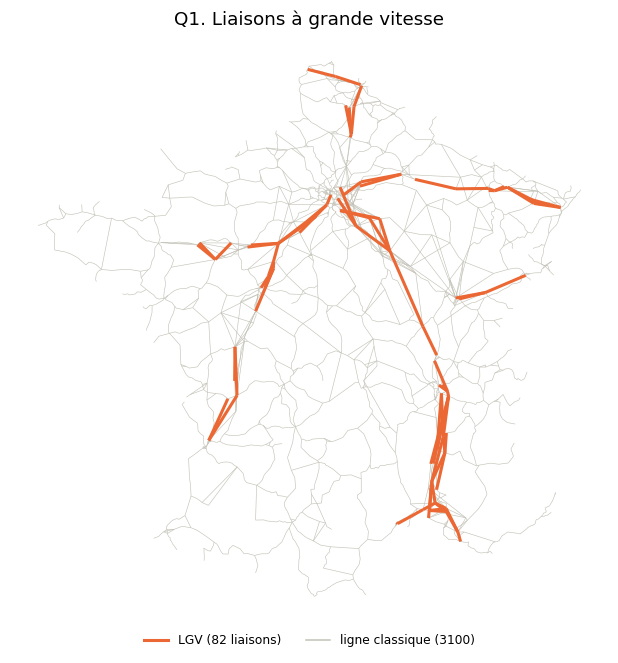

In [5]:
lgv = liaisons[liaisons["type_ligne"] == "LGV"]
fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, zip(liaisons.source, liaisons.target))
tracer_liaisons(ax, zip(lgv.source, lgv.target), couleur=ORANGE, epaisseur=2)
ax.legend(handles=[Line2D([], [], color=ORANGE, lw=2, label=f"LGV ({len(lgv)} liaisons)"),
                   Line2D([], [], color=GRIS, lw=1, label=f"ligne classique ({len(liaisons) - len(lgv)})")],
          **SOUS_CARTE)
carte(ax, "Q1. Liaisons à grande vitesse")
plt.savefig(FIGURES / "Q1_LGV.png", bbox_inches="tight")
plt.show()

Figure 1 — Les lignes à grande vitesse. Carte en placement géographique ; en orange, les 82 liaisons classées LGV, en gris les lignes classiques.

Réponse : les LGV forment une étoile centrée sur Paris, à quatre branches : Sud-Est vers Lyon et Marseille, Atlantique vers Bordeaux et Rennes, Nord vers Lille, Est vers Strasbourg. Seules la LGV Rhin-Rhône (Dijon-Mulhouse) et le contournement Nîmes-Montpellier ne partent pas de Paris.

In [6]:
if CYTOSCAPE:  # Style → Edge → Stroke Color et Width : colonne type_ligne, Discrete Mapping
    cy_style("Q1_LGV", BASE, noeud=2)
    p4c.set_edge_color_mapping("type_ligne", ["LGV", "classique"], [ORANGE, GRIS], mapping_type="d", style_name="Q1_LGV")
    p4c.set_edge_line_width_mapping("type_ligne", ["LGV", "classique"], [5, 1], mapping_type="d", style_name="Q1_LGV")
    cy_figure("Q1_LGV", BASE)

## Q2. Où circulent les trains ?

Notion du cours : un graphe pondéré associe un poids à chaque arête, ici le nombre de trains par jour, deux sens confondus, un mardi type. Méthode : l'épaisseur des arêtes est proportionnelle à ce poids.

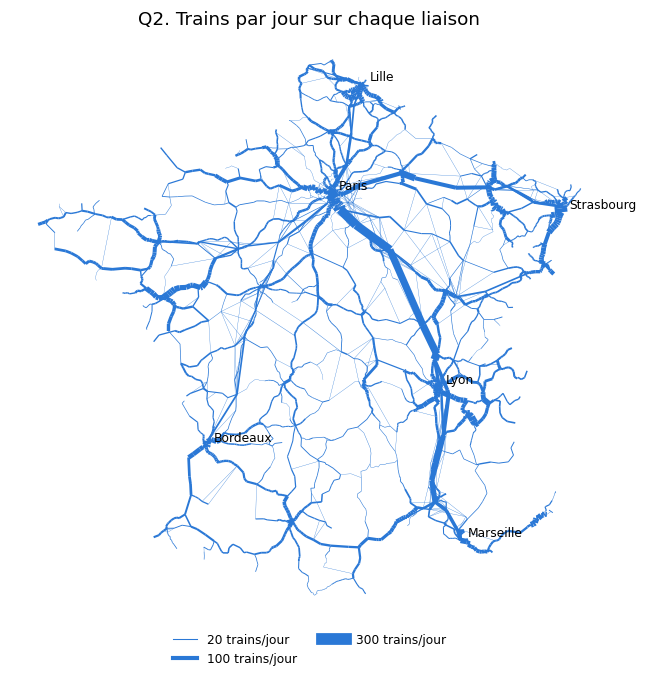

Liaisons sans aucun train ce jour-là : 20%


In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, zip(liaisons.source, liaisons.target), couleur=BLEU, epaisseur=0.2 + liaisons["nb_trains_jour"] / 40)
nommer(ax, ["75056", "69123", "59350", "67482", "13055", "33063"])  # Paris, Lyon, Lille, Strasbourg, Marseille, Bordeaux
ax.legend(handles=[Line2D([], [], color=BLEU, lw=0.2 + n / 40, label=f"{n} trains/jour") for n in (20, 100, 300)],
          **SOUS_CARTE)
carte(ax, "Q2. Trains par jour sur chaque liaison")
plt.savefig(FIGURES / "Q2_trains.png", bbox_inches="tight")
plt.show()
print(f"Liaisons sans aucun train ce jour-là : {(liaisons.nb_trains_jour == 0).mean():.0%}")

Figure 2 — Les trains d'un mardi type. Carte en placement géographique ; l'épaisseur de chaque liaison est proportionnelle à son nombre de trains par jour.

Réponse : les trains circulent surtout sur les grands axes qui partent de Paris (vers Lyon et Marseille, Strasbourg, Lille) et sur les lignes régionales en étoile autour de Lyon, Strasbourg et Lille. Une liaison sur cinq n'a aucun train ce jour-là. Ce sont surtout des liaisons de banlieue parisienne, dont les trains (Transilien, RER) manquent aux données, et des lignes fermées aux voyageurs.

In [8]:
if CYTOSCAPE:  # Style → Edge → Width : colonne nb_trains_jour, Continuous Mapping
    cy_etiquettes(["75056", "69123", "59350", "67482", "13055", "33063"])
    cy_style("Q2_trains", BASE, noeud=2)
    p4c.set_edge_line_width_mapping("nb_trains_jour", [0, float(liaisons.nb_trains_jour.max())], [0.5, 14], style_name="Q2_trains")
    p4c.set_edge_color_mapping("nb_trains_jour", [0, float(liaisons.nb_trains_jour.max())], ["#9ec5f4", BLEU], style_name="Q2_trains")
    cy_figure("Q2_trains", BASE)

## Q3. Quelles villes sont proches de tout le réseau ?

Notion du cours : la closeness $C(v) = \dfrac{n-1}{\sum_u d(v,u)}$, où $d(v,u)$ est la longueur du plus court chemin entre $v$ et $u$. Son inverse, la farness, est la distance moyenne de $v$ à toutes les autres villes. Méthode : `nx.closeness_centrality` sur le réseau principal, avec des plus courts chemins en km de rail (algorithme de Dijkstra) ; la couleur des villes code la closeness.

,ville,farness_km
91216,Épinay-sur-Orge,375.0
91326,Juvisy-sur-Orge,375.0
91136,Champlan,376.0
91027,Athis-Mons,376.0
91549,Sainte-Geneviève-des-Bois,376.0
06062,Fontan,879.0
06163,Tende,892.0
06162,La Brigue,895.0


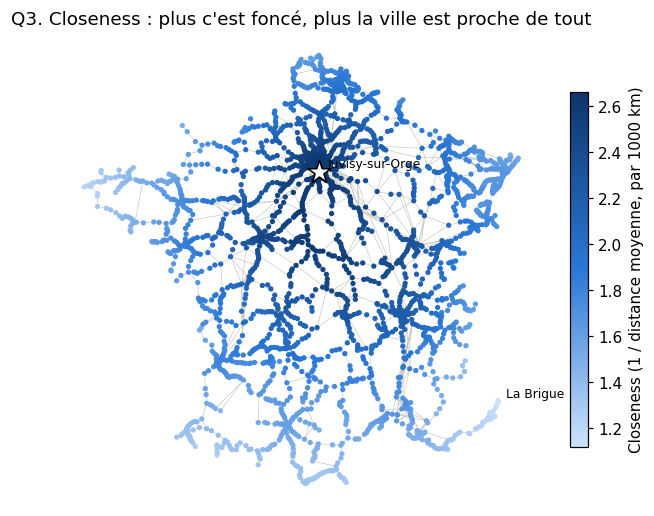

In [9]:
closeness = pd.Series(nx.closeness_centrality(P, distance=POIDS))
farness = 1 / closeness  # km en moyenne vers toutes les autres villes
display(pd.DataFrame({"ville": villes.nom, "farness_km": farness.round(0)}).dropna()
        .sort_values("farness_km").iloc[[0, 1, 2, 3, 4, -3, -2, -1]])

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, P.edges())
tracer_villes(ax, closeness * 1000, "Closeness (1 / distance moyenne, par 1000 km)")
nommer(ax, [closeness.idxmax()], etoile=True)
nommer(ax, [closeness.idxmin()])
carte(ax, "Q3. Closeness : plus c'est foncé, plus la ville est proche de tout")
plt.savefig(FIGURES / "Q3_closeness.png", bbox_inches="tight")
plt.show()

Figure 3 — Closeness. Carte en placement géographique ; plus une ville est foncée, plus elle est proche, en moyenne, de toutes les autres ; l'étoile marque la plus proche.

Réponse : la ville la plus proche de tout le réseau est Juvisy-sur-Orge (Essonne), à 375 km en moyenne de toutes les autres. Elle se trouve au croisement des lignes qui partent du sud de Paris et de la grande ceinture, la ligne qui fait le tour de Paris. La plus éloignée est La Brigue (Alpes-Maritimes), au bout de la ligne de Tende, à 895 km en moyenne. La closeness décroît régulièrement à mesure qu'on s'éloigne de l'Île-de-France : c'est la signature d'un réseau radial, organisé autour d'un centre.

In [10]:
if CYTOSCAPE:  # Style → Node → Fill Color : colonne closeness, Continuous Mapping
    cy_colonne(closeness, "closeness")
    cy_etiquettes([closeness.idxmax(), closeness.idxmin()])
    cy_style("Q3_closeness", BASE, noeud=10)
    p4c.set_node_color_mapping("closeness", [float(closeness.min()), float(closeness.max())], ["#cde2fb", "#0d366b"], style_name="Q3_closeness")
    cy_figure("Q3_closeness", BASE)

## Q4. Où est le centre du réseau, où est sa périphérie ?

Notion du cours : l'excentricité $e(v) = \max_u d(v,u)$ est la distance d'une ville à la ville la plus éloignée d'elle. Le rayon est l'excentricité minimale, atteinte au centre ; le diamètre est l'excentricité maximale, atteinte à la périphérie. La closeness regarde la distance moyenne, l'excentricité la distance au pire. Méthode : `nx.eccentricity` en km ; le plus court chemin entre les deux villes de la périphérie est le trajet le plus long de France.

Rayon : 746 km, centre : Montluçon
Diamètre : 1487 km, périphérie : La Brigue, Brest
Trajet le plus long : 144 villes traversées, via Nice, Toulon, Marseille, Nîmes, Clermont-Ferrand, Le Mans, Rennes, Brest


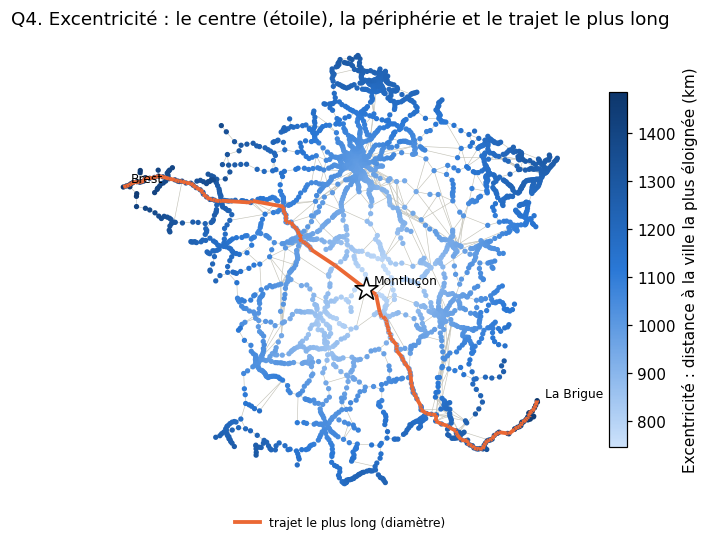

In [11]:
excentricite = pd.Series(nx.eccentricity(P, weight=POIDS))
centre = excentricite[excentricite == excentricite.min()].index
peripherie = excentricite[excentricite == excentricite.max()].index
print(f"Rayon : {excentricite.min():.0f} km, centre : {', '.join(villes.nom[centre])}")
print(f"Diamètre : {excentricite.max():.0f} km, périphérie : {', '.join(villes.nom[peripherie])}")
plus_long = nx.shortest_path(P, peripherie[0], peripherie[-1], weight=POIDS)  # le trajet le plus long de France
print(f"Trajet le plus long : {len(plus_long) - 2} villes traversées, via",
      ", ".join(villes.nom[v] for v in plus_long if villes.population[v] > 100000))

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, P.edges())
tracer_villes(ax, excentricite, "Excentricité : distance à la ville la plus éloignée (km)")
tracer_liaisons(ax, zip(plus_long, plus_long[1:]), couleur=ORANGE, epaisseur=2.5)
nommer(ax, centre, etoile=True)
nommer(ax, peripherie)
ax.legend(handles=[Line2D([], [], color=ORANGE, lw=2.5, label="trajet le plus long (diamètre)")], **SOUS_CARTE)
carte(ax, "Q4. Excentricité : le centre (étoile), la périphérie et le trajet le plus long")
plt.savefig(FIGURES / "Q4_excentricite.png", bbox_inches="tight")
plt.show()

Figure 4 — Excentricité, centre et périphérie. Carte en placement géographique ; la couleur code la distance de chaque ville à la ville la plus éloignée d'elle, l'étoile marque le centre et le tracé orange le diamètre.

Réponse : le centre est Montluçon (Allier), à 746 km au plus de toute autre ville. La périphérie oppose Brest et La Brigue, que relie le trajet le plus long de France : 1 487 km de rail pour 1 042 km à vol d'oiseau, 144 villes traversées et aucun km de LGV. Les deux mesures placent le centre à des endroits différents : la closeness le met là où se trouve la masse des villes (l'Île-de-France), l'excentricité au milieu géographique du pays. Les distances étant en km et non en temps, les LGV ne « rapprochent » pas les villes.

In [12]:
if CYTOSCAPE:  # Fill Color : colonne excentricite (Continuous) ; Size et Edge Color : colonnes de rôle (Discrete)
    cy_colonne(excentricite, "excentricite")
    role = pd.Series("", index=villes.index)
    role[list(centre)] = "centre"
    role[list(peripherie)] = "périphérie"
    cy_colonne(role, "role_q4")
    chemin = pd.Series("", index=liaisons.cle)
    chemin[[cle_arete(a, b) for a, b in zip(plus_long, plus_long[1:])]] = "trajet le plus long"
    cy_colonne(chemin, "chemin_q4", table="edge")
    cy_etiquettes(list(centre) + list(peripherie))
    cy_style("Q4_excentricite", BASE, noeud=10)
    p4c.set_node_color_mapping("excentricite", [float(excentricite.min()), float(excentricite.max())], ["#cde2fb", "#0d366b"], style_name="Q4_excentricite")
    p4c.set_node_size_mapping("role_q4", ["centre", "périphérie"], [45, 30], mapping_type="d", style_name="Q4_excentricite")
    p4c.set_edge_color_mapping("chemin_q4", ["trajet le plus long"], [ORANGE], mapping_type="d", style_name="Q4_excentricite")
    p4c.set_edge_line_width_mapping("chemin_q4", ["trajet le plus long"], [6], mapping_type="d", style_name="Q4_excentricite")
    cy_figure("Q4_excentricite", BASE)

## Q5. Quels sont les points névralgiques ?

Notion du cours : la betweenness d'une ville est la part des plus courts chemins, entre toutes les paires de villes, qui passent par elle ; l'edge betweenness est la même mesure pour une liaison (algorithme de Brandes). Une ville de forte betweenness est un point de passage obligé, comme un métabolite par lequel passent de nombreuses voies dans un réseau métabolique. Méthode : la taille et la couleur des villes codent la betweenness, l'épaisseur des liaisons l'edge betweenness, avec des plus courts chemins en km.

,ville,betweenness
75056,Paris,0.290
93066,Saint-Denis,0.163
60175,Creil,0.140
18279,Vierzon,0.139
69123,Lyon,0.133
95268,Garges-lès-Gonesse,0.132
95019,Arnouville,0.132
95280,Goussainville,0.132


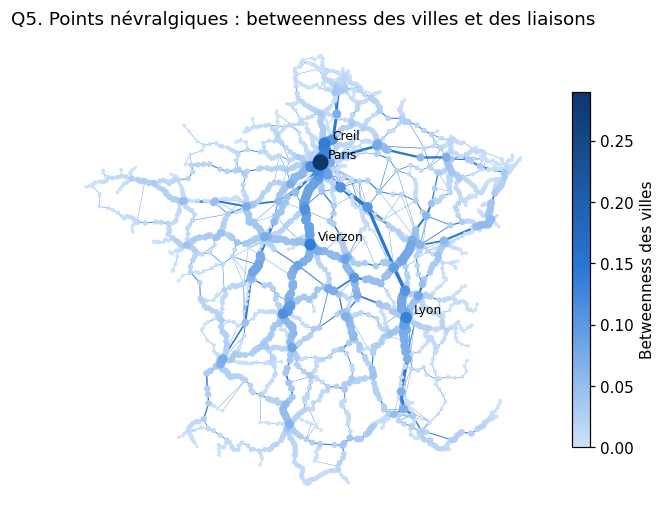

In [13]:
betweenness = pd.Series(nx.betweenness_centrality(P, weight=POIDS))
eb = nx.edge_betweenness_centrality(P, weight=POIDS)
liaisons["edge_betweenness"] = [eb.get((a, b), eb.get((b, a), 0)) for a, b in zip(liaisons.source, liaisons.target)]
nevralgiques = betweenness.nlargest(8).index
display(pd.DataFrame({"ville": villes.nom[nevralgiques], "betweenness": betweenness[nevralgiques].round(3)}))

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, zip(liaisons.source, liaisons.target), couleur=BLEU, epaisseur=0.2 + 25 * liaisons["edge_betweenness"])
tracer_villes(ax, betweenness, "Betweenness des villes", taille=2 + 300 * betweenness)
nommer(ax, [v for v in nevralgiques if villes.region[v] != "11"][:4] + ["75056"])  # hors banlieue, pour la lisibilité
carte(ax, "Q5. Points névralgiques : betweenness des villes et des liaisons")
plt.savefig(FIGURES / "Q5_betweenness.png", bbox_inches="tight")
plt.show()

Figure 5 — Points névralgiques. Carte en placement géographique ; taille et couleur des villes : betweenness ; épaisseur des liaisons : edge betweenness.

Réponse : le point névralgique principal est Paris, par où passent 29 % des plus courts chemins. Viennent ensuite la banlieue nord (Saint-Denis, Creil), passage obligé vers Lille, puis Vierzon (Cher) et Lyon. Vierzon, gare peu fréquentée, est incontournable parce que s'y croisent l'axe Paris-Toulouse et la ligne transversale Nantes-Lyon. Les liaisons les plus épaisses forment l'ossature du réseau : Paris-Orléans-Limoges-Toulouse et Paris-Lyon-Marseille.

In [14]:
if CYTOSCAPE:  # Node Size : colonne betweenness ; Edge Width : colonne edge_betweenness (Continuous Mapping)
    cy_colonne(betweenness, "betweenness")
    cy_colonne(liaisons.set_index("cle")["edge_betweenness"], "edge_betweenness", table="edge")
    cy_etiquettes([v for v in nevralgiques if villes.region[v] != "11"][:4] + ["75056"])
    cy_style("Q5_betweenness", BASE)
    p4c.set_node_size_mapping("betweenness", [0, float(betweenness.max())], [4, 60], style_name="Q5_betweenness")
    p4c.set_node_color_mapping("betweenness", [0, float(betweenness.max())], ["#cde2fb", "#0d366b"], style_name="Q5_betweenness")
    p4c.set_edge_line_width_mapping("edge_betweenness", [0, float(liaisons.edge_betweenness.max())], [0.5, 12], style_name="Q5_betweenness")
    cy_figure("Q5_betweenness", BASE)

## Q6. Que se passe-t-il si on retire les villes les plus importantes ?

Notion du cours : la robustesse d'un réseau. On retire des villes, puis on observe la plus grande composante connexe (combien de villes restent reliées entre elles) et la longueur des plus courts chemins. Un point d'articulation est une ville dont le retrait coupe le réseau en morceaux.

Méthode : quatre tests. Le premier retire Paris, la ville de plus forte betweenness, et regarde les trajets de la promotion vers Rouen. Le deuxième retire tour à tour chaque point d'articulation pour trouver celui qui isole le plus de villes. Le troisième retire les villes une à une, soit par ordre de betweenness décroissante (attaque ciblée), soit au hasard (panne aléatoire). Le quatrième retire les 10 villes de plus forte betweenness et mesure les composantes, les trajets coupés et l'allongement des plus courts chemins.

In [15]:
ROUEN = "76540"  # notre université
ORIGINES = {"Paris": "75056", "Évry": "91228", "Nantes": "44109", "Dijon": "21231",
            "Lyon": "69123", "Montpellier": "34172", "Toulouse": "31555"}  # villes de la promotion


def trajets_vers_rouen(H):
    """Plus court chemin (km) de chaque ville de la promotion présente dans H jusqu'à Rouen (None si coupé)."""
    d = nx.single_source_dijkstra_path_length(H, ROUEN, weight=POIDS)
    return {nom: d.get(v) for nom, v in ORIGINES.items() if v in H}


# Test 1 : sans Paris
sans_paris = P.copy()
sans_paris.remove_node(ORIGINES["Paris"])
test1 = pd.DataFrame({"km avec Paris": trajets_vers_rouen(P), "km sans Paris": trajets_vers_rouen(sans_paris)}).dropna()
test1["allongement_km"] = test1["km sans Paris"] - test1["km avec Paris"]
print(f"Sans Paris : {sans_paris.number_of_nodes() - len(max(nx.connected_components(sans_paris), key=len))} ville(s) isolée(s)")
display(test1.round(0))

Sans Paris : 0 ville(s) isolée(s)


,km avec Paris,km sans Paris,allongement_km
Évry,154.0,154.0,0.0
Nantes,476.0,476.0,0.0
Dijon,438.0,439.0,1.0
Lyon,580.0,581.0,1.0
Montpellier,886.0,886.0,0.0
Toulouse,827.0,827.0,0.0


In [16]:
# Test 2 : le retrait de quel point d'articulation isole le plus de villes ?
isolees = {}
for v in nx.articulation_points(P):
    H = P.copy()
    H.remove_node(v)
    isolees[v] = P.number_of_nodes() - 1 - len(max(nx.connected_components(H), key=len))
isolees = pd.Series(isolees).sort_values(ascending=False)
print(f"{len(isolees)} points d'articulation ({len(isolees) / P.number_of_nodes():.0%} des villes)")

pire = isolees.index[0]
H = P.copy()
H.remove_node(pire)
coupees = set(P) - max(nx.connected_components(H), key=len) - {pire}
print(f"Pire retrait : {villes.nom[pire]}, qui coupe {len(coupees)} villes du réseau")

318 points d'articulation (12% des villes)
Pire retrait : Carnoules, qui coupe 34 villes du réseau


In [17]:
# Test 3 : retraits successifs, attaque ciblée contre panne aléatoire
def part_reliee(ordre, n=300, pas=10):
    """Retire les villes de `ordre` une à une ; part des villes restant dans la plus grande composante."""
    H, resultat = P.copy(), {0: 1.0}
    for i, v in enumerate(ordre[:n], start=1):
        H.remove_node(v)
        if i % pas == 0:
            resultat[i] = len(max(nx.connected_components(H), key=len)) / P.number_of_nodes()
    return pd.Series(resultat)


attaque = part_reliee(list(betweenness.sort_values(ascending=False).index))
random.seed(1)
panne = sum(part_reliee(random.sample(list(P), 300)) for _ in range(10)) / 10  # moyenne de 10 tirages

In [18]:
# Test 4 : retrait, une à une, des 10 villes de plus forte betweenness
top10 = list(betweenness.nlargest(10).index)
random.seed(2)
autres = [v for v in P if v not in top10]
paires = [tuple(random.sample(autres, 2)) for _ in range(300)]  # 300 trajets tirés au hasard, les mêmes à chaque étape
reference = {(a, b): nx.shortest_path_length(P, a, b, weight=POIDS) for a, b in paires}


def connectivite(H):
    # composantes connexes, part des villes dans la plus grande, trajets coupés et allongement des autres
    composantes = list(nx.connected_components(H))
    coupes, allongements = 0, []
    for a, b in paires:
        try:
            allongements.append(nx.shortest_path_length(H, a, b, weight=POIDS) / reference[(a, b)] - 1)
        except nx.NetworkXNoPath:
            coupes += 1
    return {"composantes": len(composantes), "plus grande composante (%)": 100 * max(map(len, composantes)) / P.number_of_nodes(),
            "trajets coupés (sur 300)": coupes, "allongement moyen (%)": 100 * np.mean(allongements)}


sans_top10_g = P.copy()
etapes = [{"ville retirée": "aucune", **connectivite(sans_top10_g)}]
for v in top10:
    sans_top10_g.remove_node(v)
    etapes.append({"ville retirée": villes.nom[v], **connectivite(sans_top10_g)})
etapes = pd.DataFrame(etapes)
display(etapes.round(2))
detachees = set(sans_top10_g) - max(nx.connected_components(sans_top10_g), key=len)
print("Villes détachées du réseau principal :", ", ".join(villes.nom[list(detachees)]))

,ville retirée,composantes,plus grande composante (%),trajets coupés (sur 300),allongement moyen (%)
0,aucune,1,100.00,0,0.00
1,Paris,1,99.96,0,0.81
2,Saint-Denis,1,99.92,0,1.07
3,Creil,1,99.88,0,2.28
4,Vierzon,1,99.85,0,3.86
5,Lyon,1,99.81,0,4.56
6,Garges-lès-Gonesse,1,99.77,0,4.56
7,Arnouville,1,99.73,0,4.56
8,Goussainville,2,99.54,0,4.56
9,Louvres,2,99.54,0,4.56


Villes détachées du réseau principal : Chantilly, Orry-la-Ville


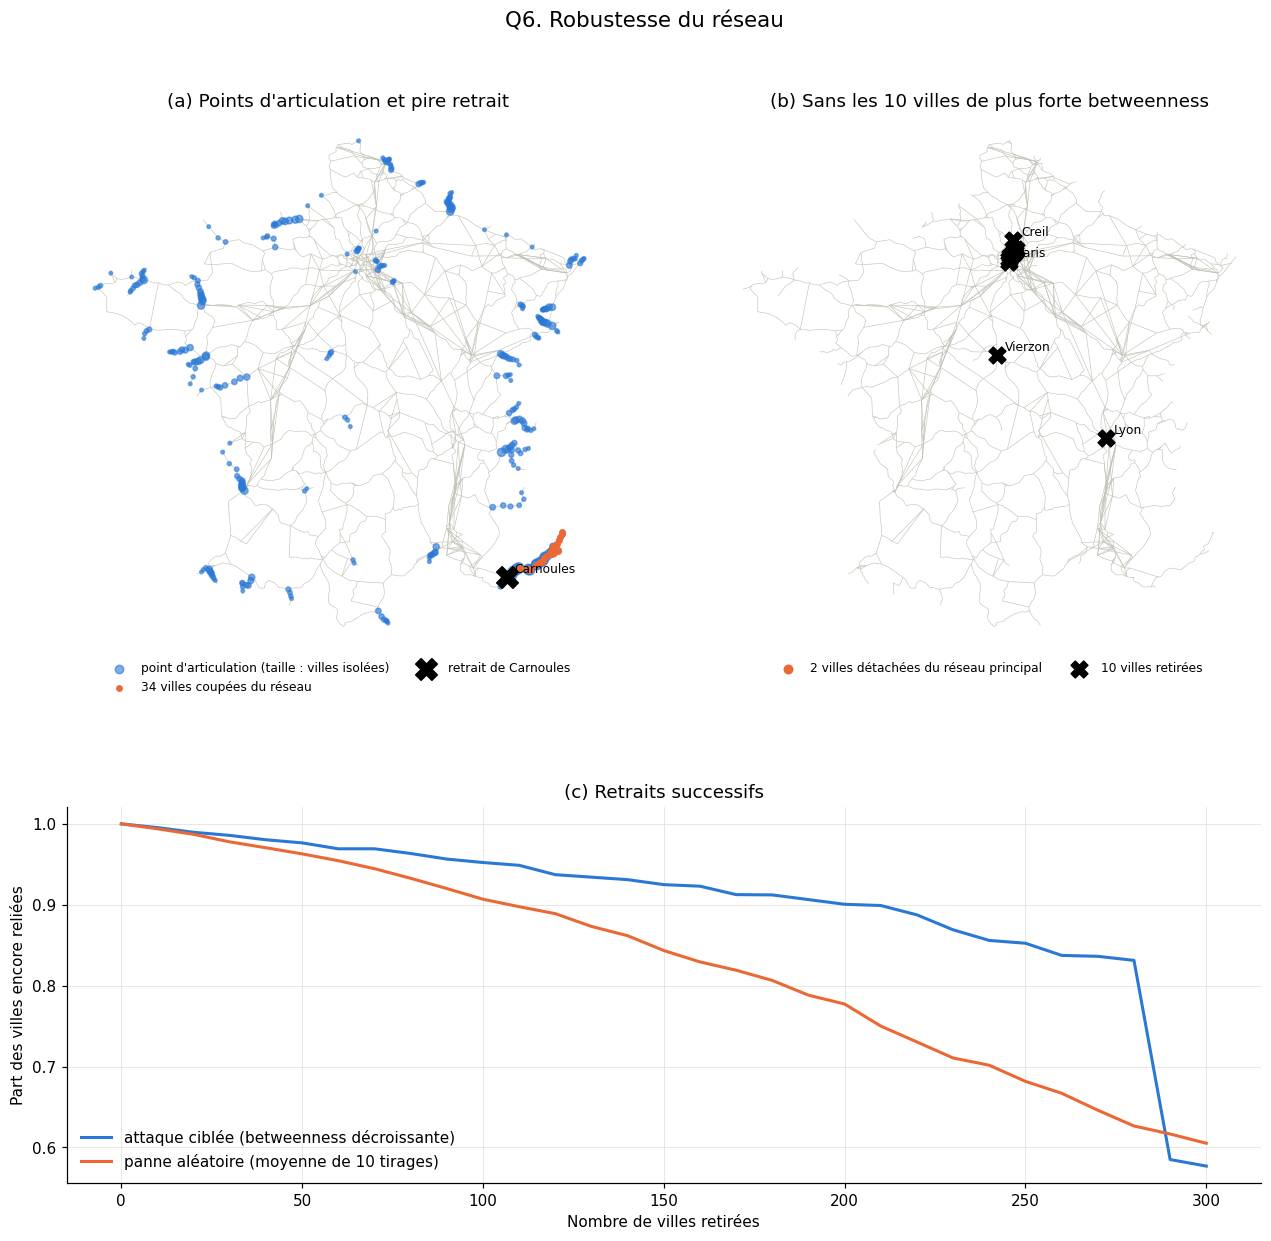

In [19]:
fig = plt.figure(figsize=(14, 13))
grille = fig.add_gridspec(2, 2, height_ratios=[1.6, 1], hspace=0.25)

# (a) points d'articulation et effet du pire retrait
ax = fig.add_subplot(grille[0, 0])
tracer_liaisons(ax, P.edges())
art = isolees[isolees > 0]
ax.scatter(villes.lon[art.index], villes.lat[art.index], s=4 + 1.5 * art, color=BLEU, alpha=0.6, zorder=2,
           label="point d'articulation (taille : villes isolées)")
tracer_liaisons(ax, P.subgraph(coupees | {pire}).edges(), couleur=ORANGE, epaisseur=2.5)
ax.scatter(villes.lon[list(coupees)], villes.lat[list(coupees)], s=12, color=ORANGE, zorder=3,
           label=f"{len(coupees)} villes coupées du réseau")
ax.scatter(villes.lon[pire], villes.lat[pire], s=200, marker="X", color="black", zorder=4, label=f"retrait de {villes.nom[pire]}")
nommer(ax, [pire])
ax.legend(**SOUS_CARTE)
carte(ax, "(a) Points d'articulation et pire retrait")

# (b) le réseau sans ses 10 villes de plus forte betweenness
ax = fig.add_subplot(grille[0, 1])
tracer_liaisons(ax, sans_top10_g.edges())
ax.scatter(villes.lon[list(detachees)], villes.lat[list(detachees)], s=30, color=ORANGE, zorder=2,
           label=f"{len(detachees)} villes détachées du réseau principal")
ax.scatter(villes.lon[top10], villes.lat[top10], s=120, marker="X", color="black", zorder=3, label="10 villes retirées")
nommer(ax, [v for v in top10 if villes.region[v] != "11"] + ["75056"])
ax.legend(**SOUS_CARTE)
carte(ax, "(b) Sans les 10 villes de plus forte betweenness")

# (c) retraits successifs : attaque ciblée contre panne aléatoire
ax = fig.add_subplot(grille[1, :])
ax.plot(attaque, color=BLEU, lw=2, label="attaque ciblée (betweenness décroissante)")
ax.plot(panne, color=ORANGE, lw=2, label="panne aléatoire (moyenne de 10 tirages)")
ax.set_xlabel("Nombre de villes retirées")
ax.set_ylabel("Part des villes encore reliées")
ax.grid(color="#e1e0d9", lw=0.5)
ax.legend(frameon=False, loc="lower left")
ax.set_title("(c) Retraits successifs")

fig.suptitle("Q6. Robustesse du réseau", fontsize=14, y=0.93)
plt.savefig(FIGURES / "Q6_robustesse.png", bbox_inches="tight")
plt.show()

Figure 6 — Robustesse du réseau. (a) Carte en placement géographique des points d'articulation, en bleu (taille : nombre de villes isolées par leur retrait), avec le pire retrait (croix). (b) Le réseau privé de ses 10 villes de plus forte betweenness. (c) Part des villes encore reliées quand on retire les villes une à une.

Réponse : presque rien ne se coupe, mais les trajets s'allongent ; le réseau est redondant au centre et fragile en périphérie. Sans Paris, aucune ville n'est isolée et les trajets vers Rouen s'allongent d'1 km au plus, car la grande ceinture contourne la capitale. Sans les 10 villes de plus forte betweenness, 99,5 % des villes restent reliées et aucun des 300 trajets tirés au hasard n'est coupé (b). Les trajets s'allongent en revanche de 4,6 % en moyenne, surtout à cause de Vierzon (+1,6 point), Creil (+1,2), Paris (+0,8) et Lyon (+0,7). Les cinq dernières villes retirées, sur la même ligne que Saint-Denis et Creil, n'ajoutent plus rien : une fois cette ligne coupée, elles ne portent plus aucun plus court chemin.

Les vraies fragilités sont en périphérie. 12 % des villes sont des points d'articulation, surtout sur des lignes en cul-de-sac, où chaque gare coupe la suite de la ligne. Le pire retrait est Carnoules (Var), sur la seule ligne qui dessert la Côte d'Azur (Marseille-Vintimille) : il coupe 34 villes du reste du réseau (a). Pour la même raison, les pannes aléatoires dégradent le réseau plus vite que l'attaque ciblée jusqu'à environ 280 retraits (c). Une panne au hasard tombe souvent sur une ligne en cul-de-sac, alors que les villes centrales sont dans des zones maillées, où il existe des itinéraires de secours. Au-delà, l'attaque fait s'effondrer le réseau, de 83 % à 58 % de villes reliées.

In [20]:
if CYTOSCAPE:  # Node Size : colonne villes_isolees ; puis copie du réseau et Edit → Delete Selected Nodes
    cy_colonne(isolees.reindex(villes.index, fill_value=0), "villes_isolees")
    etat = pd.Series("", index=villes.index)
    etat[list(coupees)] = "coupée"
    cy_colonne(etat, "etat_q6")
    cy_etiquettes([pire])
    copie = p4c.clone_network(BASE)  # on supprime la ville dans une copie, pour garder le réseau complet
    p4c.select_nodes([pire], by_col="cle", preserve_current_selection=False, network=copie)
    p4c.delete_selected_nodes(network=copie)
    cy_style("Q6_articulation", copie, noeud=4)
    p4c.set_node_size_mapping("villes_isolees", [0, float(isolees.max())], [4, 40], style_name="Q6_articulation")
    p4c.set_node_color_mapping("etat_q6", ["coupée"], [ORANGE], mapping_type="d", default_color="#9ec5f4", style_name="Q6_articulation")
    cy_figure("Q6_articulation", copie)

    # même chose sans les 10 villes : sélection des 10 villes (Select → Nodes), Edit → Delete Selected Nodes
    etat = pd.Series("principal", index=villes.index)
    etat[list(detachees)] = "détachée"
    cy_colonne(etat, "etat_top10")
    sans_top10 = p4c.clone_network(BASE)
    p4c.select_nodes(top10, by_col="cle", preserve_current_selection=False, network=sans_top10)
    p4c.delete_selected_nodes(network=sans_top10)
    cy_style("Q6_sans_top10", sans_top10, noeud=4, etiquette=None)
    p4c.set_node_color_mapping("etat_top10", ["principal", "détachée"], ["#9ec5f4", ORANGE], mapping_type="d", style_name="Q6_sans_top10")
    p4c.set_node_size_mapping("etat_top10", ["principal", "détachée"], [4, 14], mapping_type="d", style_name="Q6_sans_top10")
    cy_figure("Q6_sans_top10", sans_top10)

## Q7. Quels trajets la promotion emprunte-t-elle vers Rouen ?

Notion du cours : le plus court chemin pondéré (algorithme de Dijkstra), hypothèse « parcimonieuse » qui ne tient pas toujours dans la réalité ; le sous-graphe formé par plusieurs chemins ; la vue schématique, comme la carte globale KEGG ou le plan de métro de Tokyo montrés en cours (*« the map is not the territory »*).

Méthode : de Paris, Évry, Nantes, Dijon, Lyon, Montpellier et Toulouse vers Rouen, notre université, on compare trois distances. Le vol d'oiseau est la ligne droite. Le plus court chemin dans le graphe emprunte toutes les voies exploitées, mesurées le long du tracé. Le trajet réel est le plus court chemin sur les seules liaisons où circule au moins un train ce mardi-là ; en Île-de-France, faute de données Transilien, toutes les liaisons sont gardées.

Le plan de métro est dessiné par un algorithme schématique écrit pour ce rapport, inspiré des plans de métro octolinéaires (Nöllenburg et Wolff, 2011, qui résolvent ce problème par programmation linéaire en nombres entiers ; on utilise ici une heuristique simple). Les stations retenues sont les villes de départ, Rouen, les villes où deux trajets se rejoignent et les villes de plus de 100 000 habitants hors Île-de-France. Chaque station est d'abord déplacée par une loupe radiale centrée sur Paris : sa distance r au centre devient 2√r, ce qui agrandit la région parisienne. Elle est ensuite arrondie sur une grille d'un demi-degré, en décalant les stations qui tomberaient sur une case déjà prise. Chaque tronçon est tracé en une diagonale à 45° suivie d'un segment horizontal ou vertical. Les tronçons partagés par plusieurs trajets sont dessinés côte à côte, par décalage parallèle des polylignes avec des angles en onglet.

In [21]:
def vol_oiseau_km(a, b):
    """Distance en ligne droite (km) ; un degré de longitude vaut 111,32 x cos(46,5°) km en France."""
    return math.hypot((villes.lon[a] - villes.lon[b]) * 111.32 * math.cos(math.radians(46.5)),
                      (villes.lat[a] - villes.lat[b]) * 110.57)


idf = set(villes.index[villes.region == "11"])
desservi = P.edge_subgraph([(a, b) for a, b, n in P.edges(data="nb_trains_jour") if n > 0 or (a in idf and b in idf)])

trajets = []
for nom, origine in ORIGINES.items():
    chemin_reel = nx.shortest_path(desservi, origine, ROUEN, weight=POIDS)
    trajets.append({"trajet": f"{nom} → Rouen", "vol_oiseau": vol_oiseau_km(origine, ROUEN),
                    "graphe": nx.shortest_path_length(P, origine, ROUEN, weight=POIDS),
                    "reel": nx.path_weight(desservi, chemin_reel, weight=POIDS),
                    "villes_traversees": len(chemin_reel) - 2,
                    "via": ", ".join(villes.nom[v] for v in chemin_reel[1:-1] if villes.population[v] > 60000),
                    "chemin_reel": chemin_reel})
trajets = pd.DataFrame(trajets).set_index("trajet").sort_values("vol_oiseau")
trajets["detour_reel"] = trajets["reel"] / trajets["vol_oiseau"]
display(trajets.drop(columns="chemin_reel").round(2))

,vol_oiseau,graphe,reel,villes_traversees,via,detour_reel
trajet,,,,,,
Paris → Rouen,115.41,133.05,133.05,23,"Issy-les-Moulineaux, Versailles",1.15
Évry → Rouen,137.01,153.69,153.69,32,Versailles,1.12
Nantes → Rouen,318.89,475.99,475.99,42,"Angers, Le Mans",1.49
Dijon → Rouen,382.31,438.00,438.00,43,"Créteil, Paris, Issy-les-Moulineaux, Versailles",1.15
Lyon → Rouen,499.68,580.31,580.31,48,"Créteil, Paris, Issy-les-Moulineaux, Versailles",1.16
Toulouse → Rouen,645.72,827.48,827.48,97,"Montauban, Limoges, Versailles",1.28
Montpellier → Rouen,680.53,886.05,888.23,78,"Nîmes, Avignon, Valence, Lyon, Créteil, Paris,...",1.31


In [22]:
def decaler(points, d):
    """Polyligne décalée de `d` sur sa gauche, avec des coins en onglet (comme une voie parallèle)."""
    normales = [np.array([p[1] - q[1], q[0] - p[0]]) / np.linalg.norm(q - p) for p, q in zip(points, points[1:])]
    sortie = [points[0] + d * normales[0]]
    for n1, n2, p in zip(normales, normales[1:], points[1:-1]):
        m = (n1 + n2) / np.linalg.norm(n1 + n2)
        sortie.append(p + d * m / np.dot(m, n1))
    return sortie + [points[-1] + d * normales[-1]]


def plan_metro(ax, itineraires, pas=0.5, ecart=0.045, loupe=0.5):
    """Dessine des itinéraires (nom -> liste de villes) à la manière d'un plan de métro."""
    # 1. Stations : départs, arrivée, jonctions (ville où arrivent deux itinéraires venant de villes différentes)
    #    et villes de plus de 100 000 habitants hors Île-de-France
    precedents = {}
    for chemin in itineraires.values():
        for avant, v in zip(chemin, chemin[1:]):
            precedents.setdefault(v, set()).add(avant)
    jonctions = {v for v, avant in precedents.items() if len(avant) > 1} | {c[0] for c in itineraires.values()}
    lignes = {nom: [v for i, v in enumerate(chemin) if i == len(chemin) - 1 or v in jonctions
                    or (villes.population[v] > 100000 and villes.region[v] != "11")]
              for nom, chemin in itineraires.items()}
    # 2. Position : effet de loupe sur Paris (distance au centre élevée à la puissance `loupe`, comme sur un plan
    #    de métro où le centre est agrandi), puis arrondi sur une grille, sans deux stations sur la même case
    centre = np.array([villes.lon[ORIGINES["Paris"]] * 0.69, villes.lat[ORIGINES["Paris"]]])
    position, occupees = {}, set()
    for v in dict.fromkeys(s for stations in lignes.values() for s in stations):
        p = np.array([villes.lon[v] * 0.69, villes.lat[v]]) - centre
        r = np.linalg.norm(p)
        p = p / r * 2 * r ** loupe if r > 0 else p
        x, y = round(p[0] / pas) * pas, round(p[1] / pas) * pas
        while (x, y) in occupees:
            x += pas
        occupees.add((x, y))
        position[v] = np.array([x, y])
    # 3. Tronçons : une diagonale à 45° puis un segment horizontal ou vertical. Les lignes qui partagent un tronçon
    #    sont dessinées côte à côte, toujours dans le même ordre, comme des voies parallèles
    troncons = {}
    for nom, stations in lignes.items():
        for u, v in zip(stations, stations[1:]):
            troncons.setdefault((u, v), []).append(nom)
    for (u, v), noms in troncons.items():
        a, b = position[u], position[v]
        milieu = a + min(abs(b - a)) * np.sign(b - a)
        points = [a] + [p for p in (milieu, b) if not np.allclose(p, a)]
        points = [p for i, p in enumerate(points) if i == 0 or not np.allclose(p, points[i - 1])]
        noms = sorted(noms, key=list(itineraires).index)
        for k, nom in enumerate(noms):
            xs, ys = zip(*decaler(points, ecart * (k - (len(noms) - 1) / 2)))
            ax.plot(xs, ys, color=COULEURS[nom], lw=3.5, solid_capstyle="round", solid_joinstyle="round")
    # 4. Stations : cercles blancs ; départs et arrivée plus grands, nommés au-dessus, jonctions nommées en dessous
    for v, (x, y) in position.items():
        terminus = v in ORIGINES.values() or v == ROUEN
        ax.scatter(x, y, s=170 if terminus else 110, c="white", edgecolors="black", linewidths=2 if terminus else 1.2, zorder=3)
        voisins = [position[w][0] for u, w in troncons if u == v] + [position[u][0] for u, w in troncons if w == v]
        a_gauche = terminus and np.mean(voisins) > x  # nom du côté opposé à la ligne
        ax.annotate(villes.nom[v], (x, y), xytext=(-10, 6) if a_gauche else (8, 6) if terminus else (8, -13),
                    textcoords="offset points", ha="right" if a_gauche else "left",
                    fontsize=9 if terminus else 8, fontweight="bold" if terminus else "normal")
    ax.legend(handles=[Line2D([], [], color=c, lw=5, label=n) for n, c in COULEURS.items()], loc="lower left", frameon=False)
    ax.set_aspect("equal")
    ax.set_axis_off()
    return position, troncons

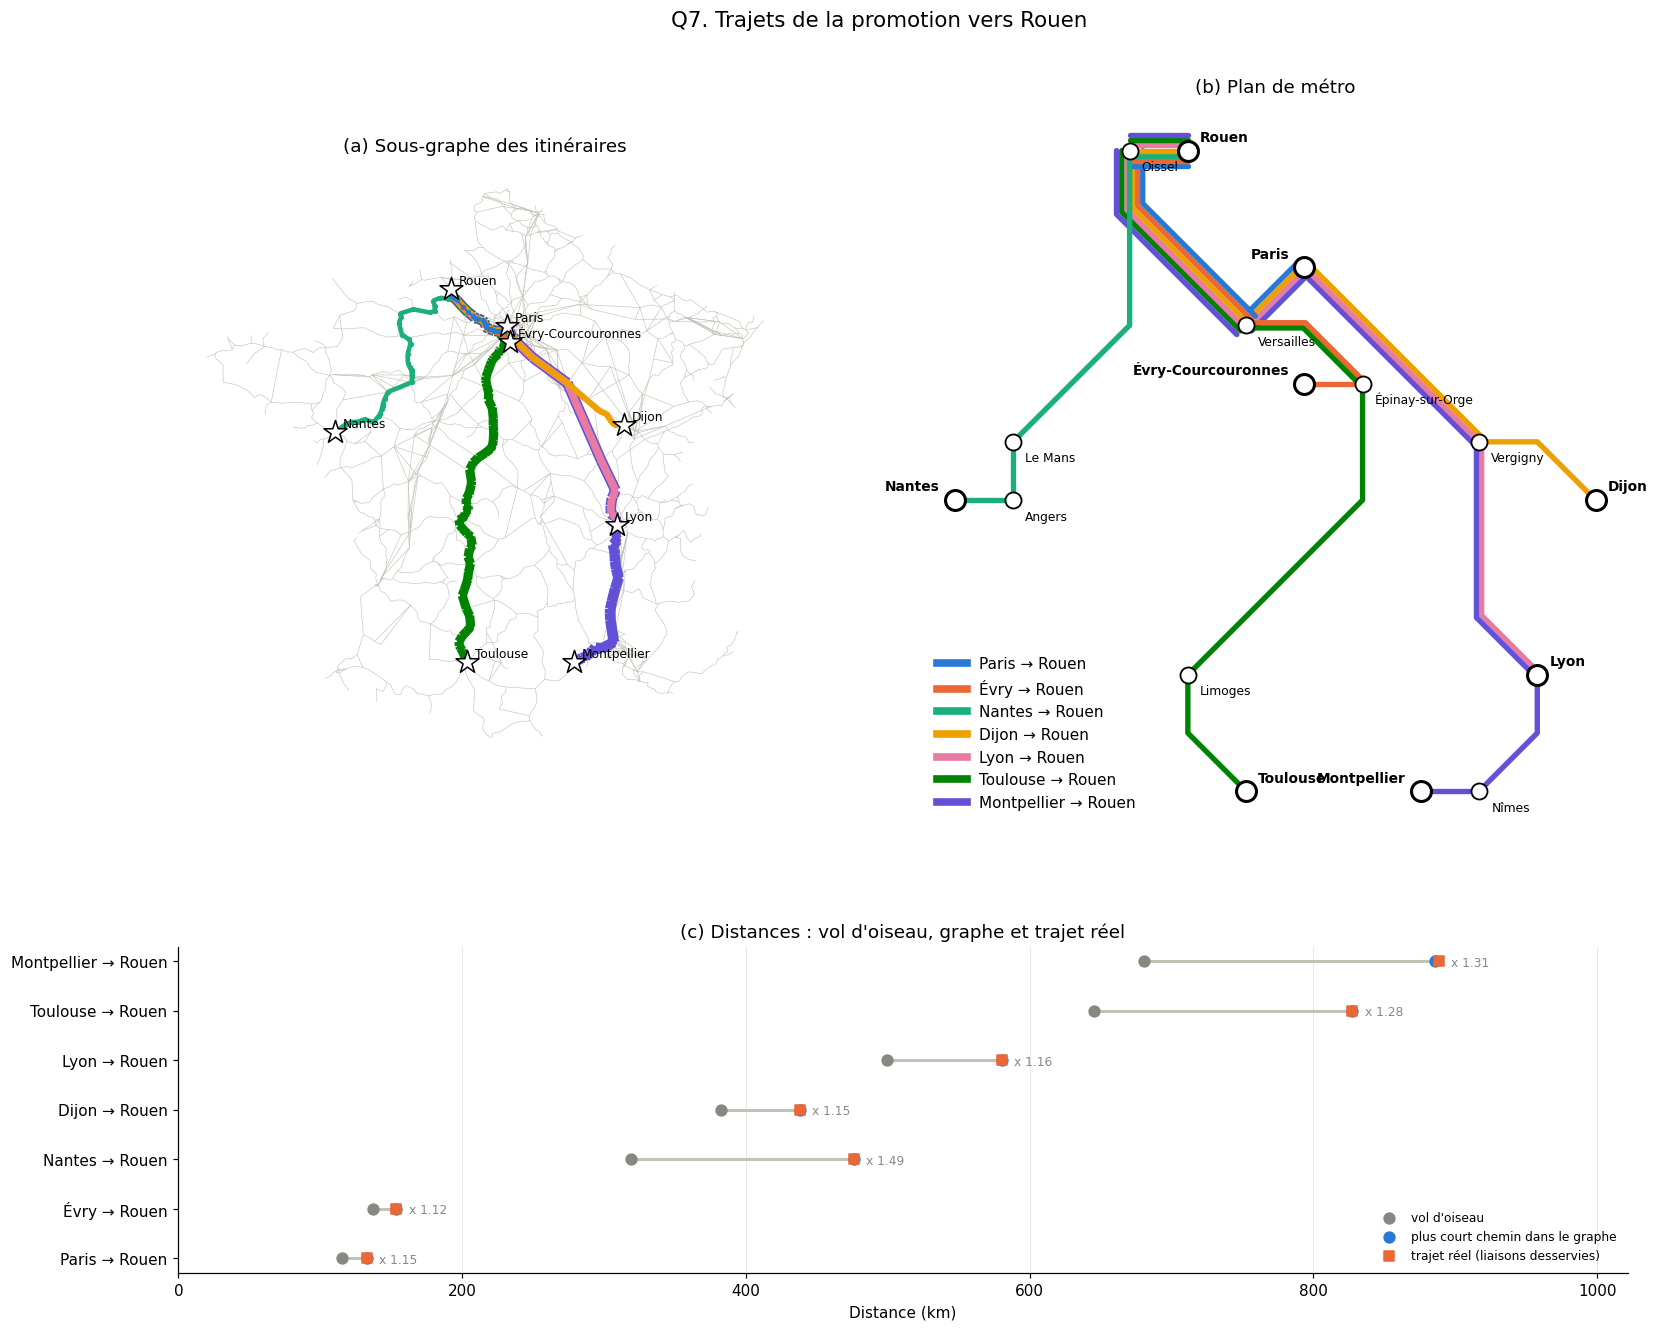

In [23]:
COULEURS = dict(zip(trajets.index, [BLEU, ORANGE, "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))
fig = plt.figure(figsize=(17, 14))
grille = fig.add_gridspec(2, 2, height_ratios=[2.3, 1], width_ratios=[1, 1.15])

# (a) sous-graphe des itinéraires, sur la carte
ax = fig.add_subplot(grille[0, 0])
tracer_liaisons(ax, P.edges())
for k, (trajet, chemin) in enumerate(trajets["chemin_reel"][::-1].items()):  # du plus long au plus court
    tracer_liaisons(ax, zip(chemin, chemin[1:]), couleur=COULEURS[trajet], epaisseur=7 - k)
    ax.scatter(villes.lon[chemin], villes.lat[chemin], s=6, color=COULEURS[trajet], zorder=2)
nommer(ax, list(ORIGINES.values()) + [ROUEN], etoile=True)
carte(ax, "(a) Sous-graphe des itinéraires")

# (b) les mêmes itinéraires en plan de métro (légende des couleurs commune à (a) et (b))
ax = fig.add_subplot(grille[0, 1])
position_metro, troncons_metro = plan_metro(ax, trajets["chemin_reel"].to_dict())
ax.set_title("(b) Plan de métro")

# (c) vol d'oiseau, plus court chemin et trajet réel
ax = fig.add_subplot(grille[1, :])
y = range(len(trajets))
ax.hlines(y, trajets.vol_oiseau, trajets[["graphe", "reel"]].max(axis=1), color=GRIS, lw=2)
ax.scatter(trajets.vol_oiseau, y, color="#898781", s=50, label="vol d'oiseau", zorder=2)
ax.scatter(trajets.graphe, y, color=BLEU, s=50, label="plus court chemin dans le graphe", zorder=3)
ax.scatter(trajets.reel, y, color=ORANGE, marker="s", s=45, label="trajet réel (liaisons desservies)", zorder=4)
for i, (x, r) in enumerate(zip(trajets[["graphe", "reel"]].max(axis=1), trajets.detour_reel)):
    ax.annotate(f"x {r:.2f}", (x, i), xytext=(8, -3), textcoords="offset points", fontsize=8, color="#898781")
ax.set_yticks(list(y), trajets.index)
ax.set_xlabel("Distance (km)")
ax.set_xlim(0, trajets[["graphe", "reel"]].max().max() * 1.15)
ax.grid(axis="x", color="#e1e0d9", lw=0.5)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title("(c) Distances : vol d'oiseau, graphe et trajet réel")

fig.suptitle("Q7. Trajets de la promotion vers Rouen", fontsize=14, y=0.93)
plt.savefig(FIGURES / "Q7_trajets_rouen.png", bbox_inches="tight")
plt.show()

Figure 7 — Les trajets de la promotion vers Rouen. (a) Sous-graphe des sept trajets réels, en placement géographique. (b) Les mêmes trajets en plan de métro (algorithme schématique décrit ci-dessus), avec les mêmes couleurs. (c) Pour chaque trajet, vol d'oiseau, plus court chemin dans le graphe et trajet réel, avec à droite le facteur de détour (distance en train / vol d'oiseau).

Réponse : les trajets forment un arbre dont Rouen est la racine, propriété des plus courts chemins vers un même nœud. Six trajets sur sept passent par Versailles avant de rejoindre la ligne Paris-Rouen ; seul celui de Nantes arrive par l'ouest, via Angers et Le Mans. Le train allonge les trajets de 12 à 49 % par rapport à la ligne droite. Le plus fort détour est Nantes → Rouen (x 1,49 : 476 km de rail pour 319 km), faute de ligne directe entre la Loire et la Normandie. Trajet réel et plus court chemin coïncident, sauf pour Montpellier → Rouen (+2 km).

Ces trajets restent ceux d'un graphe et non d'un voyageur. Le graphe ne compte pas les changements de train, et le regroupement des gares d'une ville rend gratuit le passage d'une gare parisienne à une autre. En km, le trajet Paris → Rouen passe par Issy-les-Moulineaux et Versailles, alors que les trains réels partent de Saint-Lazare : l'écart de distance est faible, mais ce n'est pas l'itinéraire qu'on prendrait.

In [24]:
if CYTOSCAPE:  # plan de métro : nouveau réseau (stations, tronçons) placé aux positions calculées ci-dessus
    stations = pd.DataFrame({"id": list(position_metro), "nom": [villes.nom[v] for v in position_metro]})
    stations["terminus"] = stations.id.isin(list(ORIGINES.values()) + [ROUEN]).map({True: "oui", False: "non"})
    troncons = pd.DataFrame([(u, v, nom) for (u, v), noms in troncons_metro.items() for nom in noms],
                            columns=["source", "target", "trajet"])
    xy = pd.DataFrame(position_metro, index=["x", "y"]).T * 100
    metro = cy_reseau(stations, troncons, "Plan de métro vers Rouen", xy.x, -xy.y)
    cy_style("Q7_metro", metro, noeud=14, arete=6, etiquette="nom")
    p4c.set_node_color_default("white", style_name="Q7_metro")
    p4c.set_node_border_width_default(2, style_name="Q7_metro")
    p4c.set_node_size_mapping("terminus", ["oui", "non"], [26, 14], mapping_type="d", style_name="Q7_metro")
    p4c.set_edge_color_mapping("trajet", list(COULEURS), list(COULEURS.values()), mapping_type="d", style_name="Q7_metro")
    cy_figure("Q7_plan_metro", metro)

    # trajets sur la carte : Edge Color, colonne trajet_rouen (Discrete Mapping)
    trajet_arete = pd.Series("", index=liaisons.cle)
    for trajet, chemin in trajets["chemin_reel"][::-1].items():  # une liaison partagée prend la couleur du trajet le plus court
        trajet_arete[[cle_arete(a, b) for a, b in zip(chemin, chemin[1:])]] = trajet
    cy_colonne(trajet_arete, "trajet_rouen", table="edge")
    cy_etiquettes(list(ORIGINES.values()) + [ROUEN])
    cy_style("Q7_promotion", BASE, noeud=3)
    p4c.set_edge_color_mapping("trajet_rouen", list(COULEURS), list(COULEURS.values()), mapping_type="d", style_name="Q7_promotion")
    p4c.set_edge_line_width_mapping("trajet_rouen", list(COULEURS), [6] * len(COULEURS), mapping_type="d", style_name="Q7_promotion")
    cy_figure("Q7_promotion", BASE)

## Q8. Les régions sont-elles inégalement desservies ?

Notion du cours : les attributs des nœuds (région, population) permettent de résumer le graphe par groupe. Le graphe quotient regroupe toutes les villes d'une même région en un seul nœud ; une arête entre deux régions porte le nombre de liaisons qui les relient, de même qu'on regroupe les métabolites par voie métabolique.

Méthode : on rapporte chaque mesure à la taille de la région (tables `regions.csv` et `departements.csv`) : part des communes qui ont une gare, part de la population qui vit dans une commune avec gare, villes desservies ou non. La Corse, dont les voies ne font pas partie du RFN, n'apparaît pas. Le graphe quotient est construit par `nx.quotient_graph` ; chaque région est placée au barycentre de ses villes, et chaque nom est écrit du côté où il ne croise ni arête ni autre région.

,nom,communes,communes_avec_gare,part_communes_avec_gare,part_population_avec_gare,villes_desservies,villes_non_desservies
code,,,,,,,
28,Normandie,2644.0,104.0,3.93,33.2,95.0,9.0
53,Bretagne,1202.0,110.0,9.15,34.4,104.0,6.0
27,Bourgogne-Franche-Comté,3685.0,190.0,5.16,38.8,186.0,4.0
75,Nouvelle-Aquitaine,4293.0,308.0,7.17,39.2,294.0,14.0
84,Auvergne-Rhône-Alpes,4025.0,292.0,7.25,40.9,287.0,5.0
24,Centre-Val de Loire,1754.0,152.0,8.67,42.1,151.0,1.0
76,Occitanie,4446.0,248.0,5.58,43.1,243.0,5.0
52,Pays de la Loire,1228.0,122.0,9.93,44.0,117.0,5.0
44,Grand Est,5115.0,351.0,6.86,44.2,317.0,34.0


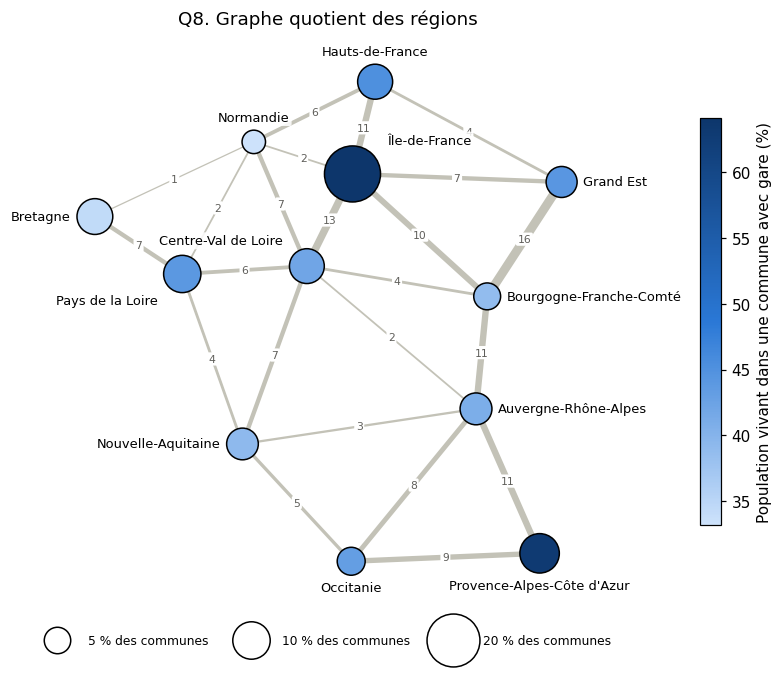

Départements où la part de population avec gare est la plus faible


,nom,communes,communes_avec_gare,part_communes_avec_gare,part_population_avec_gare
6,Ardèche,335.0,3.0,0.90,4.9
30,Gers,458.0,4.0,0.87,18.8
68,Haute-Saône,536.0,7.0,1.31,20.5
3,Alpes-de-Haute-Provence,198.0,4.0,2.02,21.9
51,Mayenne,240.0,9.0,3.75,23.1
38,Landes,327.0,15.0,4.59,23.2
41,Haute-Loire,257.0,18.0,7.00,23.2
21,Creuse,255.0,12.0,4.71,23.4


In [25]:
regions = pd.read_csv(DONNEES / "regions.csv", dtype={"code": str}).set_index("code")
departements = pd.read_csv(DONNEES / "departements.csv", dtype={"code": str})
display(regions[["nom", "communes", "communes_avec_gare", "part_communes_avec_gare", "part_population_avec_gare",
                 "villes_desservies", "villes_non_desservies"]].sort_values("part_population_avec_gare"))

# Graphe quotient : un nœud par région, une arête quand des liaisons relient deux régions (poids = nombre de liaisons)
blocs = [set(groupe.index) for _, groupe in villes.loc[list(P)].groupby("region")]
R = nx.quotient_graph(P, blocs, relabel=False)
R = nx.relabel_nodes(R, {bloc: villes.region[next(iter(bloc))] for bloc in R})
pos_region = {r: (villes.lon[villes.region == r].mean(), villes.lat[villes.region == r].mean()) for r in R}

fig, ax = plt.subplots(figsize=(9, 8))
for a, b, poids in R.edges(data="weight"):
    ax.plot(*zip(pos_region[a], pos_region[b]), color=GRIS, lw=0.5 + poids / 3, zorder=1)
    ax.annotate(poids, np.mean([pos_region[a], pos_region[b]], axis=0), fontsize=7, color="#5f5e5a", ha="center",
                va="center", zorder=3, bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
taille = {r: 60 * regions.part_communes_avec_gare[r] for r in R}
x, y = zip(*[pos_region[r] for r in R])
points = ax.scatter(x, y, s=[taille[r] for r in R], c=[regions.part_population_avec_gare[r] for r in R],
                    cmap=BLEUS, edgecolors="black", zorder=4)
plt.colorbar(points, ax=ax, shrink=0.6, pad=0.12, label="Population vivant dans une commune avec gare (%)")
# nom de chaque région, du côté où il ne croise ni arête ni autre région
COTE = {"11": (1, 0.8), "28": (0, 1), "32": (0, 1), "44": (1, 0), "53": (-1, 0), "52": (-1, -0.8), "24": (-1, 0.8),
        "27": (1, 0), "84": (1, 0), "75": (-1, 0), "76": (0, -1), "93": (0, -1)}
for r in R:
    dx, dy = COTE.get(r, (0, -1))
    rayon = taille[r] ** 0.5 / 2 + 4  # rayon du disque, en points
    ax.annotate(regions.nom[r], pos_region[r], xytext=(dx * rayon, dy * rayon), textcoords="offset points", fontsize=8.5,
                ha="left" if dx > 0 else "right" if dx < 0 else "center",
                va="bottom" if dy > 0 else "top" if dy < 0 else "center", zorder=5,
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.85))
ax.legend(handles=[plt.scatter([], [], s=60 * p, color="white", edgecolors="black", label=f"{p} % des communes")
                   for p in (5, 10, 20)], **{**SOUS_CARTE, "ncol": 3, "columnspacing": 2.5, "handletextpad": 1.5, "borderpad": 1.5})
carte(ax, "Q8. Graphe quotient des régions")
ax.margins(0.1)
plt.savefig(FIGURES / "Q8_regions.png", bbox_inches="tight")
plt.show()

colonnes = ["nom", "communes", "communes_avec_gare", "part_communes_avec_gare", "part_population_avec_gare"]
print("Départements où la part de population avec gare est la plus faible")
display(departements.nsmallest(8, "part_population_avec_gare")[colonnes])

Figure 8 — Le graphe quotient des régions. Un nœud par région, placé au barycentre de ses villes ; la taille code la part des communes qui ont une gare, la couleur la part de la population qui vit dans une commune avec gare ; le nombre sur une arête est celui des liaisons entre les deux régions.

Réponse : oui, les régions sont inégalement desservies. L'Île-de-France et Provence-Alpes-Côte d'Azur sont les mieux couvertes, avec environ 63 % de la population dans une commune avec gare, contre 33 et 34 % seulement en Normandie et en Bretagne. Les liaisons entre régions sont elles aussi inégales. La Normandie, région de Rouen, n'est reliée à l'Île-de-France que par 2 liaisons, un goulot d'étranglement pour les trajets de la promotion. La Bretagne n'est reliée qu'aux Pays de la Loire (7 liaisons) et à la Normandie (1), alors que la paire la plus liée, Grand Est - Bourgogne-Franche-Comté, compte 16 liaisons. Les villes qui ont une gare mais aucun train se concentrent dans les Hauts-de-France et le Grand Est, sur d'anciennes lignes industrielles et frontalières. À l'échelle des départements, l'Ardèche est un cas extrême : 3 communes sur 335 ont une gare (4,9 % de la population), car la rive droite du Rhône n'a plus de trains de voyageurs.

In [26]:
if CYTOSCAPE:  # graphe quotient : nouveau réseau (une région = un nœud), tailles et couleurs par Continuous Mapping
    noeuds = regions.loc[list(R)].reset_index().rename(columns={"code": "id"})
    aretes = pd.DataFrame([(a, b, w) for a, b, w in R.edges(data="weight")], columns=["source", "target", "liaisons"])
    xy = pd.DataFrame(pos_region, index=["lon", "lat"]).T
    graphe_regions = cy_reseau(noeuds, aretes, "Graphe des régions", xy.lon * 100, -xy.lat * 145)
    cy_style("Q8_regions", graphe_regions, arete=2, etiquette="nom")
    p4c.set_node_size_mapping("part_communes_avec_gare", [0, float(regions.part_communes_avec_gare.max())], [10, 90], style_name="Q8_regions")
    p4c.set_node_color_mapping("part_population_avec_gare", [30, 65], ["#cde2fb", "#0d366b"], style_name="Q8_regions")
    p4c.set_edge_line_width_mapping("liaisons", [1, float(aretes.liaisons.max())], [1, 12], style_name="Q8_regions")
    p4c.set_edge_label_mapping("liaisons", style_name="Q8_regions")
    cy_figure("Q8_regions", graphe_regions)

## Q9. Quelles villes ne sont pas connectées ?

Notion du cours : les composantes connexes. Une ville peut être déconnectée de deux façons. Dans l'infrastructure, elle n'appartient pas au réseau principal, et aucune voie ne la relie au reste. Dans le service, sa gare est reliée au réseau, mais aucun train ne s'y arrête un mardi type.

Hors du réseau principal : Tremblay-En-France, Audun-le-Tiche
Villes avec gare mais sans train un mardi type : 119


,nom,departement,population,nb_gares
id,,,,
44035,La Chapelle-sur-Erdre,44,20690.0,4
30028,Bagnols-sur-Cèze,30,18112.0,1
57757,Yutz,57,17391.0,1
76447,Montivilliers,76,15478.0,2
71014,Autun,71,13172.0,1
59152,Comines,59,12731.0,2
59386,Marquette-lez-Lille,59,12622.0,1
27284,Gisors,27,12410.0,1
59636,Wambrechies,59,11012.0,1


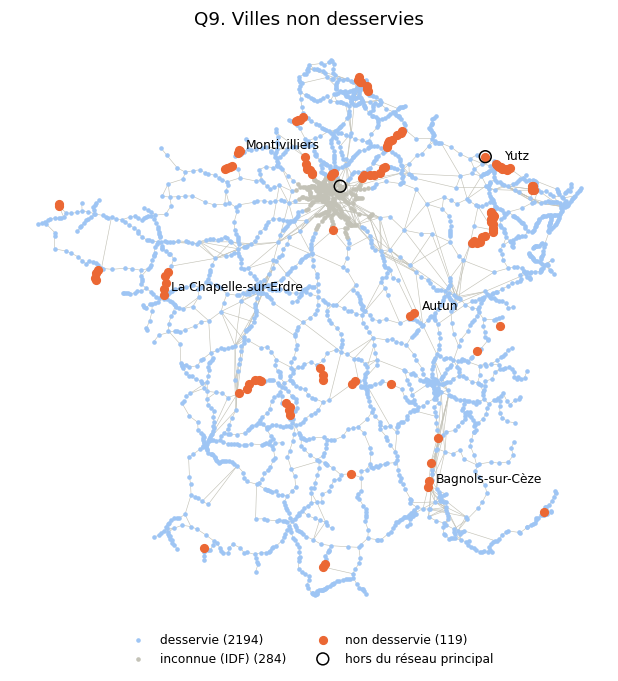

In [27]:
hors_reseau = villes[~villes.reseau_principal]
non_desservies = villes[villes.statut_desserte == "non desservie"]
print("Hors du réseau principal :", ", ".join(hors_reseau.nom))
print(f"Villes avec gare mais sans train un mardi type : {len(non_desservies)}")
display(non_desservies.nlargest(10, "population")[["nom", "departement", "population", "nb_gares"]])

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, G.edges())
for statut, couleur, taille in [("desservie", "#9ec5f4", 4), ("inconnue (IDF)", GRIS, 4), ("non desservie", ORANGE, 25)]:
    v = villes[villes.statut_desserte == statut]
    ax.scatter(v.lon, v.lat, s=taille, color=couleur, label=f"{statut} ({len(v)})", zorder=2)
ax.scatter(hors_reseau.lon, hors_reseau.lat, s=60, facecolors="none", edgecolors="black", label="hors du réseau principal", zorder=3)
nommer(ax, non_desservies.nlargest(5, "population").index)
ax.legend(**SOUS_CARTE)
carte(ax, "Q9. Villes non desservies")
plt.savefig(FIGURES / "Q9_non_desservies.png", bbox_inches="tight")
plt.show()

Figure 9 — Les villes non connectées. Carte en placement géographique ; en orange, les villes qui ont une gare mais aucun train ce mardi-là ; cercles noirs : villes hors du réseau principal ; en gris, les villes d'Île-de-France, dont la desserte est inconnue faute de données Transilien et RER.

Réponse : dans l'infrastructure, deux villes seulement sont hors du réseau principal. Audun-le-Tiche (Moselle) n'est reliée à la France que par le Luxembourg. Tremblay-en-France (gare Aéroport-Charles-de-Gaulle 2 TGV) est coupée par un raccordement que le prétraitement n'a pas trouvé : c'est une erreur de construction du graphe, pas une réalité. Dans le service, 119 villes ont une gare mais aucun train, par exemple Bagnols-sur-Cèze et Pont-Saint-Esprit sur la rive droite du Rhône, Yutz, Montivilliers ou Autun. Certaines sont desservies par un moyen de transport absent des horaires SNCF, comme le tram-train à La Chapelle-sur-Erdre, près de Nantes, ou le car TER ailleurs.

In [28]:
if CYTOSCAPE:  # Style → Node → Fill Color et Size : colonne statut_desserte, Discrete Mapping
    cy_etiquettes(non_desservies.nlargest(5, "population").index)
    cy_style("Q9_desserte", BASE)
    p4c.set_node_color_mapping("statut_desserte", ["desservie", "inconnue (IDF)", "non desservie"],
                               ["#9ec5f4", GRIS, ORANGE], mapping_type="d", style_name="Q9_desserte")
    p4c.set_node_size_mapping("statut_desserte", ["desservie", "inconnue (IDF)", "non desservie"], [5, 5, 20],
                              mapping_type="d", style_name="Q9_desserte")
    cy_figure("Q9_desserte", BASE)

## Q10. Quelles gares sont les plus connectées, et les moins connectées ?

Notion du cours : le degré $k(v)$ est le nombre de voisins d'un nœud, et la distribution des degrés $p(k)$ la part des nœuds qui ont $k$ voisins. Les réseaux métaboliques du cours ont quelques super hubs, des nœuds de très fort degré.

Méthode : on mesure le degré sur deux graphes. Dans l'infrastructure (le graphe des villes), c'est le nombre de villes voisines sur le rail. Dans le réseau desservi (`gtfs_fr_*`, une gare par nœud), c'est le nombre de gares atteintes par un train direct, sans arrêt intermédiaire. Le degré pondéré, somme des trains par jour, mesure en plus l'intensité du service.

In [29]:
degre = pd.Series(dict(G.degree()))
print("Infrastructure, degré le plus fort :", ", ".join(f"{villes.nom[v]} ({k})" for v, k in degre.nlargest(5).items()))
print(f"Infrastructure, degré 1 (terminus) : {(degre == 1).sum()} villes ; degré 0 (isolées) : {(degre == 0).sum()}")
display(villes.loc[degre[degre == 1].index].nlargest(8, "population")[["nom", "departement", "population"]])

gares_fr = pd.read_csv(DONNEES / "gtfs_fr_nodes.csv", dtype={"id": str}).set_index("id")
dessertes = pd.read_csv(DONNEES / "gtfs_fr_edges.csv", dtype={"source": str, "target": str})
D = nx.from_pandas_edgelist(dessertes, "source", "target", edge_attr="nb_trains")
degre_d = pd.Series(dict(D.degree()))
trains_d = pd.Series(dict(D.degree(weight="nb_trains")))
display(pd.DataFrame({"gare": gares_fr.nom, "gares en direct (degré)": degre_d, "trains par jour (degré pondéré)": trains_d})
        .dropna().sort_values("gares en direct (degré)", ascending=False).head(8))

Infrastructure, degré le plus fort : Tournan-en-Brie (13), Montereau-Fault-Yonne (13), Collonges-et-Premières (13), La Houssaye-en-Brie (13), Bollène (12)
Infrastructure, degré 1 (terminus) : 66 villes ; degré 0 (isolées) : 2


,nom,departement,population
29019,Brest,29,142346.0
59599,Tourcoing,59,98772.0
59183,Dunkerque,59,86263.0
50129,Cherbourg-en-Cotentin,50,78258.0
95127,Cergy,95,70906.0
83069,Hyères,83,55858.0
85194,Les Sables-d'Olonne,85,49603.0
35288,Saint-Malo,35,47439.0


,gare,gares en direct (degré),trains par jour (degré pondéré)
87723197,Lyon Part Dieu,33,715
87212027,Strasbourg,29,726
87471003,Rennes,24,383
87396002,Le Mans,22,285
87286005,Lille Flandres,22,560
87581009,Bordeaux Saint-Jean,21,466
87141002,Nancy,20,382
87611004,Toulouse Matabiau,19,355


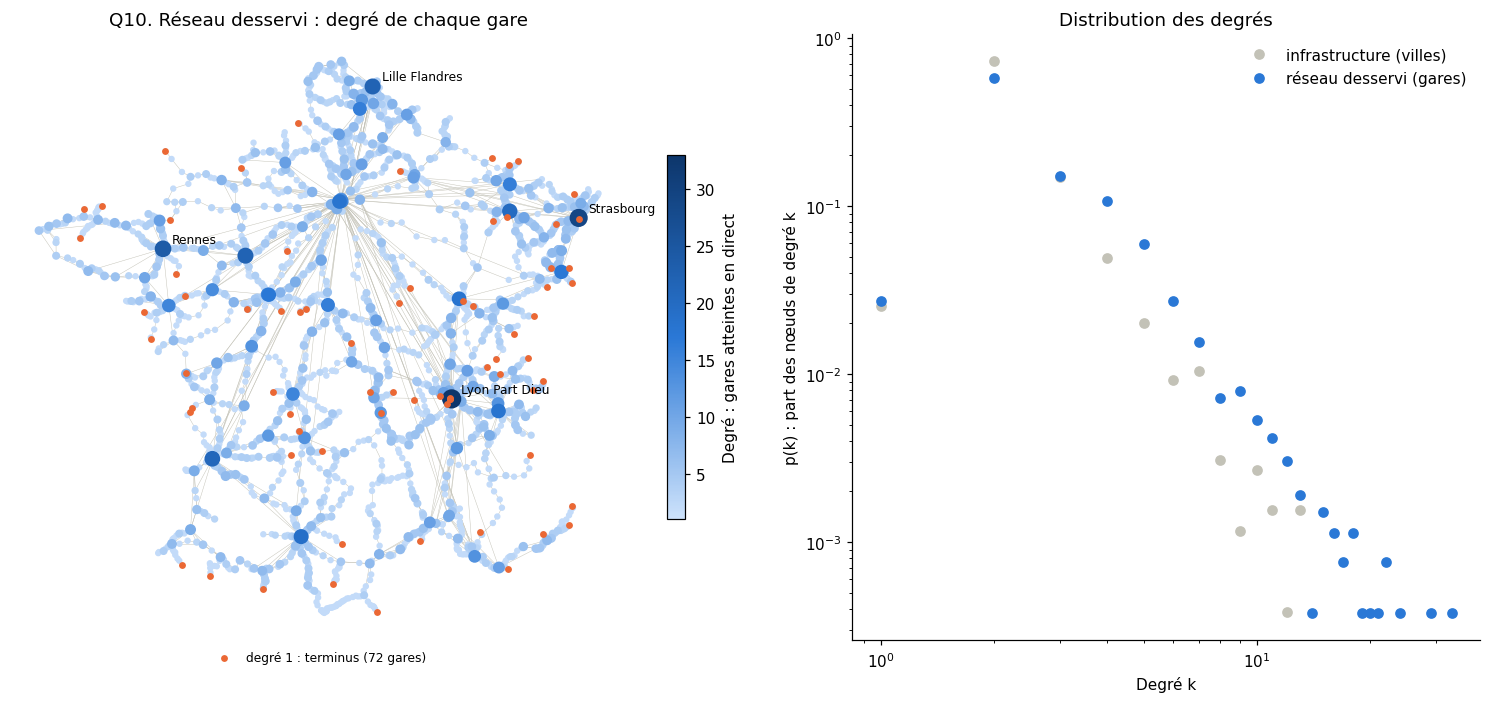

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
p = dict(zip(gares_fr.index, zip(gares_fr.lon, gares_fr.lat)))
ax.add_collection(LineCollection([(p[a], p[b]) for a, b in D.edges()], colors=GRIS, linewidths=0.3))
t = degre_d.sort_values()
points = ax.scatter(gares_fr.lon[t.index], gares_fr.lat[t.index], c=t, cmap=BLEUS, s=2 + 4 * t, zorder=2)
plt.colorbar(points, ax=ax, shrink=0.6, label="Degré : gares atteintes en direct")
un = degre_d[degre_d == 1].index
ax.scatter(gares_fr.lon[un], gares_fr.lat[un], s=12, color=ORANGE, zorder=3, label=f"degré 1 : terminus ({len(un)} gares)")
for g in degre_d.nlargest(4).index:
    ax.annotate(gares_fr.nom[g], p[g], xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.legend(**SOUS_CARTE)
carte(ax, "Q10. Réseau desservi : degré de chaque gare")
ax.autoscale()

ax = axes[1]
for donnees, couleur, nom in [(degre[degre > 0], GRIS, "infrastructure (villes)"), (degre_d, BLEU, "réseau desservi (gares)")]:
    pk = donnees.value_counts(normalize=True).sort_index()
    ax.loglog(pk.index, pk.values, "o", color=couleur, label=nom)
ax.set_xlabel("Degré k")
ax.set_ylabel("p(k) : part des nœuds de degré k")
ax.set_title("Distribution des degrés")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURES / "Q10_degre.png", bbox_inches="tight")
plt.show()

Figure 10 — Le degré des gares. À gauche, le réseau desservi en placement géographique ; taille et couleur codent le nombre de gares atteintes en direct, et les gares de degré 1 (desservies par un seul voisin) sont en orange. À droite, la distribution des degrés en échelles logarithmiques, pour l'infrastructure (gris) et le réseau desservi (bleu).

Réponse : la gare la plus connectée est Lyon Part-Dieu, qui dessert 33 gares en direct, devant Strasbourg (29) et Rennes (24) ; en trains par jour, Strasbourg passe en tête (726 contre 715). Les gares parisiennes, au départ de quelques lignes chacune, desservent peu de gares en direct. Les moins connectées sont les terminus : dans l'infrastructure, 66 villes n'ont qu'un voisin, comme Brest, Tourcoing, Dunkerque ou Cherbourg. Le réseau n'a pas de super hubs : presque toutes les villes ont un degré 2, au milieu d'une ligne, et le maximum reste faible (33 en desserte directe). Contrairement aux réseaux métaboliques, la géographie limite le nombre de voies qui partent d'une gare.

Les plus forts degrés de l'infrastructure (13) sont, eux, un artefact de construction. Tournan-en-Brie, La Houssaye-en-Brie ou Collonges-et-Premières sont au bord de lignes sans gare voyageurs (contournements fret, LGV). Le prétraitement relie alors directement ces gares à toutes celles que ces lignes atteignent, jusqu'à 106 km de distance (Tournan-en-Brie → Longueil-Sainte-Marie).

In [31]:
if CYTOSCAPE:  # Tools → Analyze Network : Cytoscape calcule lui-même la colonne Degree
    p4c.set_current_network(BASE)
    p4c.analyze_network()  # Degree, ClosenessCentrality, BetweennessCentrality, Eccentricity… ajoutés à la table
    cy_etiquettes(degre.nlargest(4).index)
    cy_style("Q10_degre", BASE)
    p4c.set_node_size_mapping("Degree", [1, float(degre.max())], [4, 40], style_name="Q10_degre")
    p4c.set_node_color_mapping("Degree", [1, 2, float(degre.max())], [ORANGE, "#cde2fb", "#0d366b"], style_name="Q10_degre")
    cy_figure("Q10_degre_infrastructure", BASE)
    # réseau desservi : un nœud par gare, une arête par paire d'arrêts consécutifs d'un train
    noeuds = gares_fr.loc[list(D)].reset_index()
    desservi_cy = cy_reseau(noeuds, dessertes, "Réseau desservi (gares)", gares_fr.lon[list(D)] * 100, -gares_fr.lat[list(D)] * 145)
    p4c.set_current_network(desservi_cy)
    p4c.analyze_network()  # Degree sur le réseau desservi
    cy_style("Q10_desservi", desservi_cy, etiquette=None)
    p4c.set_node_size_mapping("Degree", [1, float(degre_d.max())], [4, 50], style_name="Q10_desservi")
    p4c.set_node_color_mapping("Degree", [1, 2, float(degre_d.max())], [ORANGE, "#cde2fb", "#0d366b"], style_name="Q10_desservi")
    p4c.set_edge_line_width_mapping("nb_trains", [0, float(dessertes.nb_trains.max())], [0.3, 8], style_name="Q10_desservi")
    cy_figure("Q10_degre_desservi", desservi_cy)

## Q11. Quel trajet passe obligatoirement par le plus de gares ?

Notion du cours : le plus court chemin non pondéré compte les liaisons, et non les km (parcours en largeur). Le diamètre non pondéré est le plus grand nombre de liaisons qu'il faut parcourir entre deux villes, en prenant le chemin le plus direct. Méthode : le trajet qui réalise ce diamètre passe obligatoirement par le plus de gares, puisqu'aucun itinéraire entre ces deux villes ne peut en traverser moins. On le compare au trajet le plus long en km (Q4).

Err → Brest : 90 liaisons, 89 villes intermédiaires, 1767 km
via Perpignan, Béziers, Avignon, Paris, Rennes, Brest
À comparer : le trajet le plus long en km (La Brigue → Brest) traverse 144 villes


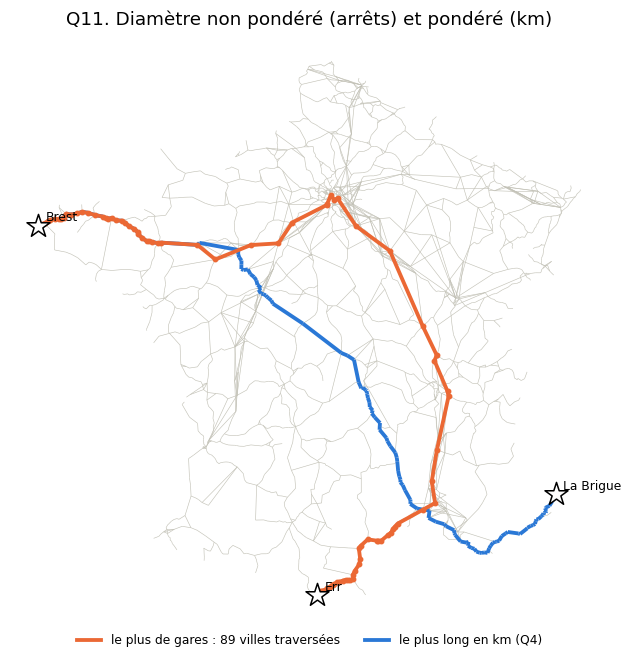

In [32]:
nb_arretes = pd.Series(nx.eccentricity(P))  # excentricité en nombre de liaisons (graphe non pondéré)
depart = nb_arretes.idxmax()
distances = nx.single_source_shortest_path_length(P, depart)
arrivee = max(distances, key=distances.get)
plus_d_arrets = nx.shortest_path(P, depart, arrivee)
print(f"{villes.nom[depart]} → {villes.nom[arrivee]} : {len(plus_d_arrets) - 1} liaisons, "
      f"{len(plus_d_arrets) - 2} villes intermédiaires, {nx.path_weight(P, plus_d_arrets, POIDS):.0f} km")
print("via", ", ".join(villes.nom[v] for v in plus_d_arrets if villes.population[v] > 80000))
print(f"À comparer : le trajet le plus long en km ({villes.nom[plus_long[0]]} → {villes.nom[plus_long[-1]]}) "
      f"traverse {len(plus_long) - 2} villes")

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, P.edges())
tracer_liaisons(ax, zip(plus_long, plus_long[1:]), couleur=BLEU, epaisseur=2.5)
tracer_liaisons(ax, zip(plus_d_arrets, plus_d_arrets[1:]), couleur=ORANGE, epaisseur=2.5)
ax.scatter(villes.lon[plus_d_arrets], villes.lat[plus_d_arrets], s=8, color=ORANGE, zorder=3)
nommer(ax, list(dict.fromkeys([depart, arrivee, plus_long[0], plus_long[-1]])), etoile=True)
ax.legend(handles=[Line2D([], [], color=ORANGE, lw=2.5, label=f"le plus de gares : {len(plus_d_arrets) - 2} villes traversées"),
                   Line2D([], [], color=BLEU, lw=2.5, label="le plus long en km (Q4)")], **SOUS_CARTE)
carte(ax, "Q11. Diamètre non pondéré (arrêts) et pondéré (km)")
plt.savefig(FIGURES / "Q11_plus_de_gares.png", bbox_inches="tight")
plt.show()

Figure 11 — Diamètre non pondéré et pondéré. Carte en placement géographique ; en orange, le trajet qui passe obligatoirement par le plus de gares ; en bleu, le trajet le plus long en km (figure 4).

Réponse : c'est le trajet d'Err (village des Pyrénées-Orientales, sur la ligne de Cerdagne) à Brest : 90 liaisons, 89 villes traversées (dont Perpignan, Béziers, Avignon, Paris et Rennes) et 1 767 km. Ce n'est pas le trajet le plus long en km (Brest → La Brigue). Le chemin qui compte le moins d'arrêts emprunte les LGV (959 km sur 1 767), où les gares sont rares, plutôt que le Massif central, où elles sont nombreuses. Plus court chemin non pondéré et pondéré ne coïncident donc pas.

In [33]:
if CYTOSCAPE:  # Fill Color : colonne Eccentricity calculée par Analyze Network (en nombre de liaisons, Q10)
    chemins = pd.Series("", index=liaisons.cle)
    chemins[[cle_arete(a, b) for a, b in zip(plus_long, plus_long[1:])]] = "le plus long en km"
    chemins[[cle_arete(a, b) for a, b in zip(plus_d_arrets, plus_d_arrets[1:])]] = "le plus de gares"
    cy_colonne(chemins, "chemin_q11", table="edge")
    cy_etiquettes(list(dict.fromkeys([depart, arrivee, plus_long[0], plus_long[-1]])))
    cy_style("Q11_arrets", BASE)
    p4c.set_node_color_mapping("Eccentricity", [float(nb_arretes.min()), float(nb_arretes.max())], ["#cde2fb", "#0d366b"], style_name="Q11_arrets")
    p4c.set_edge_color_mapping("chemin_q11", ["le plus de gares", "le plus long en km"], [ORANGE, BLEU], mapping_type="d", style_name="Q11_arrets")
    p4c.set_edge_line_width_mapping("chemin_q11", ["le plus de gares", "le plus long en km"], [6, 6], mapping_type="d", style_name="Q11_arrets")
    cy_figure("Q11_plus_de_gares", BASE)

## Contrôle : Cytoscape calcule-t-il la même chose ?

Analyze Network, lancé en Q10, calcule degré, excentricité, closeness et betweenness sans poids, en nombre de liaisons. On compare ses colonnes aux mêmes métriques sans poids calculées par NetworkX, qui doivent être identiques, puis aux métriques en km utilisées dans ce rapport, qui mesurent autre chose.

In [34]:
sans_poids = pd.DataFrame({"Degree": pd.Series(dict(P.degree())), "Eccentricity": nb_arretes,
                           "ClosenessCentrality": pd.Series(nx.closeness_centrality(P)),
                           "BetweennessCentrality": pd.Series(nx.betweenness_centrality(P))})
en_km = pd.DataFrame({"Degree": degre, "Eccentricity": excentricite,
                      "ClosenessCentrality": closeness, "BetweennessCentrality": betweenness}).loc[sans_poids.index]
if CYTOSCAPE:  # colonnes ajoutées par Analyze Network à la table des nœuds du réseau des villes
    cy = p4c.get_table_columns("node", network=BASE).set_index("cle").loc[sans_poids.index]

controle = []
for m in sans_poids:
    tete = (lambda s: s.idxmin()) if m == "Eccentricity" else (lambda s: s.idxmax())  # centre ou maximum
    ligne = {"métrique (colonne Cytoscape)": m,
             "en tête, en km (rapport)": villes.nom[tete(en_km[m])],
             "en tête, en liaisons": villes.nom[tete(sans_poids[m])],
             "corrélation de rang km / liaisons": round(en_km[m].corr(sans_poids[m], method="spearman"), 2)}
    if CYTOSCAPE:
        ligne["écart maximal Cytoscape / NetworkX"] = float((cy[m].astype(float) - sans_poids[m]).abs().max())
    controle.append(ligne)
display(pd.DataFrame(controle).set_index("métrique (colonne Cytoscape)"))

,"en tête, en km (rapport)","en tête, en liaisons",corrélation de rang km / liaisons
métrique (colonne Cytoscape),,,
Degree,Tournan-en-Brie,Tournan-en-Brie,1.00
Eccentricity,Montluçon,Colombier-Saugnieu,0.55
ClosenessCentrality,Juvisy-sur-Orge,Montereau-Fault-Yonne,0.75
BetweennessCentrality,Paris,Commune Nouvelle D'Arrou,0.33


Tableau — Cytoscape face à NetworkX. Pour chaque métrique : la ville en tête en km (ce rapport), la ville en tête en nombre de liaisons, la corrélation de rang (Spearman) entre les deux classements et, quand Cytoscape est ouvert, l'écart maximal entre Cytoscape et NetworkX sans poids. Lors de notre vérification avec Cytoscape 3.10.5, cet écart valait 0 pour le degré et l'excentricité, 1,4 × 10⁻¹⁷ pour la closeness et 2,2 × 10⁻¹⁵ pour la betweenness.

Réponse : oui pour les calculs sans poids, non pour les distances en km. Sans poids, Cytoscape et NetworkX donnent les mêmes valeurs pour les quatre métriques, à un arrondi près ; le degré de Q10 et l'excentricité en liaisons de Q11 sont donc confirmés par Cytoscape. Mais Analyze Network ignore les km, et compter des liaisons change les réponses. La ville la plus proche de tout devient Montereau-Fault-Yonne au lieu de Juvisy-sur-Orge, le centre Colombier-Saugnieu au lieu de Montluçon, et le classement par betweenness n'a presque plus rien à voir (corrélation de rang de 0,33). C'est pourquoi les métriques en km sont calculées en Python, puis seulement affichées dans Cytoscape.

## Conclusion

Le réseau ferré français est radial. Les LGV forment une étoile autour de Paris (Q1), la closeness décroît depuis l'Île-de-France (Q3) et Paris est en tête de la betweenness (Q5). Il est aussi redondant au centre et fragile en périphérie : retirer Paris ou les 10 villes les plus centrales ne coupe presque rien mais allonge les trajets, alors que les vrais points de coupure sont sur les lignes en cul-de-sac et sur la ligne Marseille-Vintimille (Q6).

Les métriques ne disent pas la même chose. Le centre est Juvisy-sur-Orge par la distance moyenne, Montluçon par la distance au pire (Q3, Q4). Le plus court chemin change selon qu'on compte des km ou des arrêts (Q4, Q11), et le degré selon qu'on regarde l'infrastructure ou le service (Q10). Ignorer les poids, comme le fait Analyze Network de Cytoscape, change le centre et le classement des points névralgiques (contrôle).

Ces résultats ont des limites. Les distances sont en km et non en temps, les changements de train ne sont pas comptés, Transilien et RER manquent aux horaires, et un seul jour est observé. Enfin, la construction du graphe laisse quelques artefacts : un raccordement manquant à Roissy (Q9), et des gares reliées à travers des lignes sans gare voyageurs (Q10).